# Sieci neuronowe

## Wstęp

Na tym laboratorium poznamy podstawy sieci neuronowych i uczenia głębokiego (**deep learning**). Laboratorium składa się z dwóch części:

1. **Część teoretyczna** - jak uczy się sieć neuronowa: neuron, funkcja kosztu, gradient i spadek wzdłuż gradientu, propagacja wsteczna, sieci MLP, trening na paczkach danych, optymalizatory, regularyzacja oraz normalizacja.

2. **Część praktyczna** - najpierw zaimplementujemy od zera w NumPy regresję logistyczną i jej trening spadkiem wzdłuż gradientu z propagacją wsteczną. Następnie przeniesiemy to samo do frameworka PyTorch (tensory, autograd, `nn.Module`, optymalizatory) i zbudujemy sieć MLP oraz różne ulepszenia.

### Wykorzystywane biblioteki

* [NumPy](https://numpy.org/)
* [Pandas](https://pandas.pydata.org/)
* [scikit-learn](https://scikit-learn.org/stable/)
* [matplotlib](https://matplotlib.org/)
* [PyTorch](https://pytorch.org/) - framework do uczenia głębokiego: tensory, automatyczne różniczkowanie, warstwy sieci i optymalizatory

### Konfiguracja środowiska

Możesz korzystać ze środowiska lokalnego z menedżerem pakietów [uv](https://docs.astral.sh/uv/) lub z [Google Colab](https://colab.research.google.com/). Wszystko zostało przetestowane z użyciem `uv` - jeżeli w trakcie pracy instalujesz biblioteki ręcznie przez `pip`, to coś może się zepsuć lub nie działać z powodu niekompatybilnych wersji.

#### Środowisko lokalne

Konfiguracja wygląda tak samo, jak w laboratoriach 1 i 2:
1. Instalacja uv [zgodnie z dokumentacją](https://docs.astral.sh/uv/getting-started/installation/) (jeżeli nie masz go jeszcze zainstalowanego)
2. Stworzenie środowiska wirtualnego: `uv venv`
3. Aktywacja środowiska wirtualnego: zgodnie z komendą wypisaną przez `uv venv`, np. `source .venv/bin/activate` na Linuxie/macOS/WSL
4. Zainstalowanie zależności z pliku `uv.lock`: `uv sync`
5. Uruchomienie Jupyter Notebooka: `uv run jupyter notebook` (samo `jupyter notebook` też zadziała w aktywowanym venv'ie)

Na Linuxie i Windowsie instalowana jest wersja PyTorcha tylko na CPU, dużo mniejsza od domyślnej wersji z obsługą kart graficznych NVIDIA - w tym laboratorium GPU nie jest potrzebne.

#### Google Colab

Jeżeli korzystasz z tej opcji, to prześlij do katalogu `/content` pliki z danymi [higgs_data.parquet](higgs_data.parquet) i [credit_data.parquet](credit_data.parquet) oraz plik `requirements.txt`. PyTorch jest w Colabie zainstalowany domyślnie, a pozostałe zależności zainstalujesz, wykonując `!pip install -r requirements.txt` w osobnej komórce notebooka.

In [ ]:
# uncomment and run if using Google Colab
# !pip install -r requirements.txt

### Podstawowe importy

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

np.set_printoptions(precision=4, suppress=True)

# Część teoretyczna

Na dotychczasowych laboratoriach zarówno do definicji modelu, jak i doboru parametrów wykorzystywaliśmy wysokopoziomowe interfejsy scikit-learn. Teraz przyjrzymy się temu, jak modele parametryczne, a w szczególności sieci neuronowe, uczą się od środka. W tej części omówimy teorię, a w części praktycznej przełożymy ją na kod.

Polecam też [serię filmów 3blue1brown](https://www.3blue1brown.com/?topic=neural-networks), która w intuicyjny sposób mówi szerzej o zagadnieniach z tego laboratorium.

**Regresja logistyczna jako neuron**

Weźmy punkty na płaszczyźnie, opisane cechami $x = (x_1, x_2)$, z dwóch klas ($y \in \{0, 1\}$). Klasy będziemy przewidywać za pomocą **regresji logistycznej**, znanej z laboratorium 2. Model liczy najpierw **logit**, czyli kombinację liniową cech z wagami $w$ i wyrazem wolnym (**bias**) $b$:

$$
z = w^\top x + b = w_1 x_1 + w_2 x_2 + b
$$

a potem przepuszcza go przez **funkcję sigmoidalną (sigmoid)** $\sigma$, która zamienia dowolną liczbę rzeczywistą na prawdopodobieństwo klasy 1:

$$
\hat p = \sigma(z) = \frac{1}{1 + e^{-z}}
$$

Model przewiduje klasę 1, gdy $\hat p \geq 0.5$, czyli gdy $z \geq 0$. **Granica decyzyjna (decision boundary)** to zbiór punktów, dla których $w_1 x_1 + w_2 x_2 + b = 0$ - jest to prosta. Wagi $w$ wyznaczają jej kierunek, a bias $b$ jej przesunięcie:

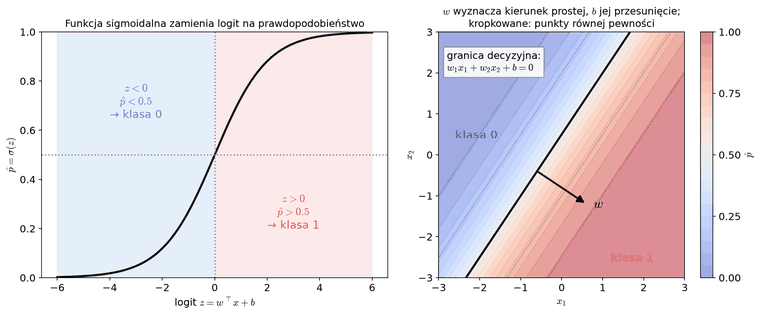

Dokładnie tak działa pojedynczy **neuron** w sieci neuronowej: liczy iloczyn skalarny wag z wejściem, dodaje bias i przepuszcza wynik przez **funkcję aktywacji (activation function)**, tutaj sigmoidę. Wagi i bias to **parametry** modelu, oznaczane razem jako $\theta = (w, b)$. Uczenie modelu to szukanie takich parametrów, dla których model popełnia jak najmniejsze błędy.

**Funkcja kosztu**

Jakość predykcji mierzymy **funkcją kosztu (loss function, cost function)**. Dla klasyfikacji binarnej używamy **binarnej entropii krzyżowej (binary cross-entropy, BCE)**, zdefiniowanej w laboratorium 2. Koszt pojedynczego punktu oznaczymy $\ell_i$, a koszt całego zbioru $L$ to średnia po $N$ punktach:

$$
\ell_i = -\left[\, y_i \log(\hat p_i) + (1 - y_i) \log(1 - \hat p_i) \,\right]
\qquad
L = BCE(y, \hat p) = \frac{1}{N} \sum_{i=1}^{N} \ell_i
$$

Koszt punktu jest bliski zeru, gdy model daje wysokie prawdopodobieństwo prawdziwej klasy, i rośnie do nieskończoności, gdy model jest pewny złej klasy. Dla regresji używa się zwykle błędu średniokwadratowego (MSE) z laboratorium 1.

Koszt zależy od parametrów modelu, więc uczenie modelu to **minimalizacja funkcji kosztu** względem $\theta$. Dla regresji logistycznej moglibyśmy użyć gotowego solvera (jak w scikit-learn), ale sieci neuronowe mają miliony parametrów i nie mają rozwiązania analitycznego. Potrzebujemy więc ogólnej metody, która zadziała dla każdego różniczkowalnego modelu - spadku wzdłuż gradientu.

**Pochodna i gradient**

[Pochodna](https://en.wikipedia.org/wiki/Derivative) $f'(x)$ to nachylenie stycznej do wykresu funkcji w punkcie $x$, czyli informacja, jak szybko i w którą stronę zmienia się funkcja, gdy minimalnie zmienimy $x$:

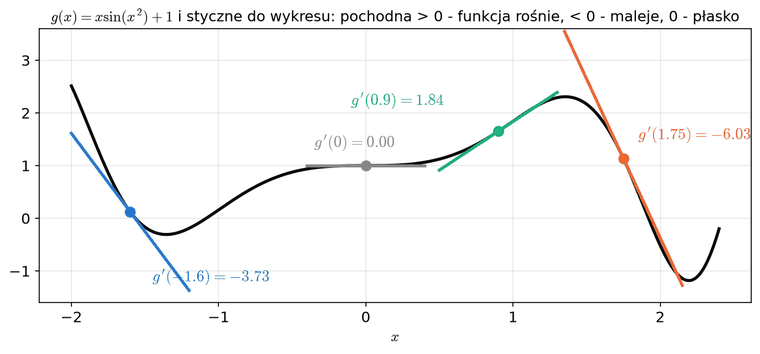

Pochodną można policzyć **analitycznie** (na kartce, z reguł różniczkowania), np. dla $f(x) = 3x^2 - 4x + 5$ mamy $f'(x) = 6x - 4$, albo [**numerycznie**](https://en.wikipedia.org/wiki/Numerical_differentiation) - przesuwając $x$ o małe $h$ i mierząc zmianę wartości funkcji. Najprostsza dokładna metoda to **różnica centralna (central difference)**:

$$
f'(x) \approx \frac{f(x+h) - f(x-h)}{2h}
$$

Pochodna numeryczna wymaga tylko możliwości policzenia funkcji, ale dla modelu z $P$ parametrami kosztuje $2P$ obliczeń kosztu. Dlatego w praktyce używa się pochodnych analitycznych, a numeryczne służą głównie do ich **sprawdzania** (*gradient checking*).

Funkcja kosztu zależy od wielu parametrów naraz. **Pochodna cząstkowa** $\frac{\partial L}{\partial w_j}$ mówi, jak zmienia się koszt, gdy zmieniamy tylko parametr $w_j$, a pozostałe są stałe. **Gradient** to wektor pochodnych cząstkowych po wszystkich parametrach, u nas $\nabla_\theta L = \left[ \frac{\partial L}{\partial w_1}, \frac{\partial L}{\partial w_2}, \frac{\partial L}{\partial b} \right]$. Gradient wskazuje kierunek, w którym koszt najszybciej **rośnie** ([z czego wynika ta zależność](https://www.khanacademy.org/math/multivariable-calculus/multivariable-derivatives/gradient-and-directional-derivatives/v/why-the-gradient-is-the-direction-of-steepest-ascent)), a jego długość - jak stromo.

**Spadek wzdłuż gradientu**

Skoro gradient wskazuje kierunek najszybszego wzrostu kosztu, to żeby koszt zmniejszyć, przesuwamy parametry w przeciwną stronę. **Spadek wzdłuż gradientu (gradient descent)** powtarza taki krok wielokrotnie:

$$
\theta \leftarrow \theta - \eta \, \nabla_\theta L
$$

gdzie $\eta$ to **stała ucząca (learning rate)**, czyli wielkość kroku. Zbyt mała stała ucząca oznacza bardzo powolny trening, a zbyt duża - przeskakiwanie minimum, oscylacje, a nawet wzrost kosztu. Jedno przejście przez cały zbiór treningowy to **epoka (epoch)**.

Trening modelu to **pętla ucząca (training loop)** złożona z czterech kroków, powtarzanych w każdej epoce:
1. **Przejście w przód (forward pass)** - liczymy predykcje $\hat p$ dla aktualnych parametrów $\theta$; na początku parametry to małe, losowe wartości.
2. **Obliczenie funkcji kosztu** - mierzymy błąd predykcji $L$.
3. **Przejście wstecz (backward pass)** - liczymy gradient $\nabla_\theta L$.
4. **Aktualizacja parametrów** - **optymalizator** (u nas spadek wzdłuż gradientu) zmienia parametry zgodnie z regułą powyżej.

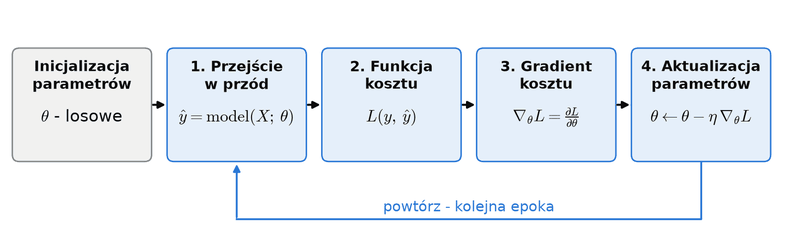

Dla regresji logistycznej funkcja kosztu jest wypukła (ma jedno minimum), ale dla sieci neuronowych już nie. Wtedy spadek wzdłuż gradientu znajduje **minimum lokalne**, zależne od punktu startowego. Animacja poniżej pokazuje spadek wzdłuż gradientu dla funkcji dwóch parametrów z kilkoma minimami, z trzech różnych punktów startowych.

In [ ]:
import tempfile
from pathlib import Path

from IPython.display import Image
from matplotlib.animation import FuncAnimation, PillowWriter


def peaks(x: np.ndarray, y: np.ndarray) -> np.ndarray:
    # function with several local minima and maxima ("peaks" from MATLAB)
    return (
        3 * (1 - x) ** 2 * np.exp(-(x**2) - (y + 1) ** 2)
        - 10 * (x / 5 - x**3 - y**5) * np.exp(-(x**2) - y**2)
        - np.exp(-((x + 1) ** 2) - y**2) / 3
    )


def peaks_gradient(x: float, y: float, h: float = 1e-5) -> np.ndarray:
    # numerical gradient with central differences
    dx = (peaks(x + h, y) - peaks(x - h, y)) / (2 * h)
    dy = (peaks(x, y + h) - peaks(x, y - h)) / (2 * h)
    return np.array([dx, dy])


# gradient descent from three starting points
lr, n_steps = 0.04, 40
paths = []
for start in [(-0.25, 1.2), (0.25, 1.2), (1.2, -0.4)]:
    theta = np.array(start)
    path = [theta]
    for _ in range(n_steps):
        theta = theta - lr * peaks_gradient(*theta)
        path.append(theta)
    paths.append(np.array(path))

# cost surface (left) and contour plot (right)
grid = np.linspace(-3, 3, 60)
grid_x, grid_y = np.meshgrid(grid, grid)
grid_z = peaks(grid_x, grid_y)

fig = plt.figure(figsize=(9, 4))
ax_3d = fig.add_subplot(1, 2, 1, projection="3d")
ax_3d.plot_surface(grid_x, grid_y, grid_z, cmap="viridis", alpha=0.6, linewidth=0)
ax_3d.view_init(elev=35, azim=-60)
ax_2d = fig.add_subplot(1, 2, 2)
ax_2d.contour(grid_x, grid_y, grid_z, levels=25, cmap="viridis")
for ax in (ax_3d, ax_2d):
    ax.set_xlabel(r"$\theta_1$")
    ax.set_ylabel(r"$\theta_2$")
ax_3d.set_zlabel("cost")

colors = ["red", "orange", "magenta"]
lines_3d = [ax_3d.plot([], [], [], "o-", color=c, ms=3)[0] for c in colors]
lines_2d = [ax_2d.plot([], [], "o-", color=c, ms=3)[0] for c in colors]
title = fig.suptitle("")
fig.tight_layout()


def draw_step(step: int) -> None:
    for path, line_3d, line_2d in zip(paths, lines_3d, lines_2d):
        visited = path[: step + 1]
        line_3d.set_data(visited[:, 0], visited[:, 1])
        line_3d.set_3d_properties(peaks(visited[:, 0], visited[:, 1]) + 0.3)
        line_2d.set_data(visited[:, 0], visited[:, 1])
    title.set_text(f"Gradient descent, step {step}")


# every step at the beginning, then every third step
frames = list(range(20)) + list(range(20, n_steps + 1, 3))
animation = FuncAnimation(fig, draw_step, frames=frames)
with tempfile.TemporaryDirectory() as tmp_dir:
    gif_path = Path(tmp_dir) / "gradient_descent.gif"
    animation.save(gif_path, writer=PillowWriter(fps=4), dpi=70)
    plt.close(fig)
    display(Image(gif_path.read_bytes()))

Każdy punkt startowy trafia do innego minimum. Tylko jeden z nich znajduje najgłębsze minimum (ok. $(0.2, -1.6)$), a pozostałe zatrzymują się w minimach lokalnych. W sieciach neuronowych z milionami parametrów nie jest to aż tak groźne: minima lokalne mają zwykle podobnie niski koszt, a większym problemem są płaskie obszary funkcji kosztu, tzw. **plateau**, na których gradient jest bliski zeru i trening prawie stoi w miejscu. Zobaczymy je w części praktycznej.

**Propagacja wsteczna**

Do spadku wzdłuż gradientu potrzebujemy gradientu kosztu po parametrach. Koszt to złożenie prostych funkcji:

$$
z_i = w^\top x_i + b, \qquad \hat p_i = \sigma(z_i), \qquad \ell_i(y_i, \hat p_i)
$$

Pochodną złożenia funkcji liczymy z **reguły łańcuchowej (chain rule)**, mnożąc pochodne kolejnych funkcji:

$$
\frac{\partial \ell_i}{\partial w_j} =
\underbrace{\frac{\partial \ell_i}{\partial \hat p_i}}_{\text{BCE}} \cdot
\underbrace{\frac{\partial \hat p_i}{\partial z_i}}_{\text{sigmoida}} \cdot
\underbrace{\frac{\partial z_i}{\partial w_j}}_{\text{logit}}
$$

**Propagacja wsteczna (backpropagation)** liczy te iloczyny od końca, czyli od kosztu w stronę parametrów. Dzięki temu część wspólna dla wszystkich parametrów, $\frac{\partial \ell_i}{\partial \hat p_i} \cdot \frac{\partial \hat p_i}{\partial z_i}$, jest liczona tylko raz. W sieci z wieloma warstwami ta sama idea działa dla każdej warstwy: gradient po parametrach warstwy liczymy z gradientu po jej wyjściu, przekazanego z warstwy następnej. Obliczenia modelu można przedstawić jako **graf obliczeń (computational graph)**, a propagacja wsteczna przechodzi go od kosztu do parametrów.

Koszt zbioru to średnia $L = \frac{1}{N} \sum_{i=1}^{N} \ell_i$, a każdy parametr wpływa na niego przez wszystkie punkty. Oznaczmy przez $\delta_i$ pochodną kosztu po logicie punktu $i$:

$$
\delta_i = \frac{\partial L}{\partial z_i} = \frac{1}{N} \cdot \frac{\partial \ell_i}{\partial \hat p_i} \cdot \frac{\partial \hat p_i}{\partial z_i}
$$

Ponieważ $\frac{\partial z_i}{\partial w_j} = x_{ij}$ oraz $\frac{\partial z_i}{\partial b} = 1$, a pochodna sumy to suma pochodnych, gradient otrzymujemy, sumując po wszystkich punktach:

$$
\frac{\partial L}{\partial w_j} = \sum_{i=1}^{N} \delta_i \, x_{ij}
\qquad
\frac{\partial L}{\partial b} = \sum_{i=1}^{N} \delta_i
$$

**Sieć neuronowa MLP**

Granica decyzyjna regresji logistycznej, czyli jednego neuronu, to zawsze prosta (w ogólności: hiperpłaszczyzna). Trening może ją tylko obracać i przesuwać, więc model nie poradzi sobie z danymi, których klas nie da się rozdzielić prostą (**nieseparowalnych liniowo**). Moglibyśmy ręcznie projektować nieliniowe cechy, ale zamiast tego użyjemy **sieci neuronowej**, która nauczy się ich sama.

**MLP (multilayer perceptron)** układa neurony w kolejne **warstwy (layers)**. Warstwy między wejściem a wyjściem to **warstwy ukryte (hidden layers)**, a ich wyjście $h$ to nowe cechy (**ukryta reprezentacja**), których sieć uczy się sama. W MLP każda warstwa jest **w pełni połączona (fully connected)**: każdy neuron dostaje na wejściu wszystkie wyjścia poprzedniej warstwy. Dla sieci z jedną warstwą ukrytą:

$$
h = \phi(x W_1 + b_1) \qquad \hat p = \sigma(h W_2 + b_2)
$$

gdzie $\phi$ to funkcja aktywacji warstwy ukrytej, $W_1$ ma kształt $d \times k$ ($d$ cech wejściowych, $k$ neuronów ukrytych), a $W_2$ - $k \times 1$. Warstwa wyjściowa to zwykła regresja logistyczna, tyle że na cechach $h$ zamiast $x$. Głębsze sieci mają po prostu więcej warstw ukrytych, każda liczona z wyjścia poprzedniej.

Warstwa wyjściowa wyznacza granicę liniową, ale w przestrzeni cech $h$, a nie w przestrzeni wejścia $x$. Neurony ukryte są nieliniowymi funkcjami wejścia, więc przekształcają dane tak, że klasy, których nie da się rozdzielić prostą w przestrzeni $x$, w przestrzeni $h$ można rozdzielić płaszczyzną. W przykładzie poniżej wystarczy dodać do $x_1$ i $x_2$ nieliniową cechę $h_3 = x_1^2 + x_2^2$, czyli kwadrat odległości od środka:

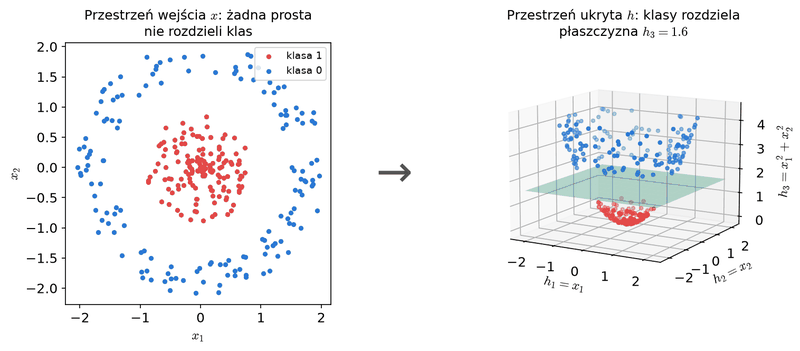

Przeniesiona z powrotem do przestrzeni $x$ granica decyzyjna jest krzywą, tutaj okręgiem $x_1^2 + x_2^2 = 1.6$. Sieć uczy się tego przekształcenia sama, razem z warstwą wyjściową. Kluczowa jest tu **nieliniowość** funkcji aktywacji - złożenie funkcji liniowych jest funkcją liniową, więc sieć bez nieliniowych aktywacji, niezależnie od liczby warstw, jest zwykłym modelem liniowym. Zgodnie z **twierdzeniem o uniwersalnej aproksymacji (universal approximation theorem)** już sieć z jedną warstwą ukrytą i nieliniową aktywacją może przybliżyć dowolną funkcję ciągłą z dowolną dokładnością, jeśli ma wystarczająco dużo neuronów.

Najpopularniejsze funkcje aktywacji to:
- **sigmoida** $\sigma(z) = \frac{1}{1 + e^{-z}}$ - wartości z $(0, 1)$, używana głównie na wyjściu sieci do klasyfikacji binarnej,
- **tangens hiperboliczny** $\tanh(z)$ - podobny kształt, ale wartości z $(-1, 1)$, wyśrodkowane w zerze,
- **ReLU (rectified linear unit)** $\mathrm{ReLU}(z) = \max(0, z)$ - domyślny wybór dla warstw ukrytych: jest tani w obliczeniach, a jego pochodna dla dodatnich $z$ wynosi 1. Pochodne sigmoidy i $\tanh$ są bliskie zeru dla dużych $|z|$ (funkcja się "nasyca"), co spowalnia trening głębokich sieci.

Jak sieć MLP przekształca dane krok po kroku, dobrze pokazuje [ten film](https://www.youtube.com/watch?v=l-9ALe3U-Fg).

In [ ]:
z = np.linspace(-5, 5, 200)
activations = {
    "sigmoid": 1 / (1 + np.exp(-z)),
    "tanh": np.tanh(z),
    "ReLU": np.maximum(0, z),
}

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for name, values in activations.items():
    axes[0].plot(z, values, lw=2, label=name)
    axes[1].plot(z, np.gradient(values, z), lw=2, label=name)
axes[0].set_title("Activation functions")
axes[1].set_title("Derivatives of activation functions")
for ax in axes:
    ax.axhline(0, color="black", lw=0.5)
    ax.set_xlabel("z")
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylim(-1.5, 3)
fig.tight_layout()
plt.show()

Do klasyfikacji wieloklasowej warstwa wyjściowa ma tyle neuronów, ile klas, a zamiast sigmoidy używa się funkcji **softmax**, która zamienia wektor logitów na rozkład prawdopodobieństwa (wartości z $(0, 1)$ sumujące się do 1). Funkcją kosztu jest wtedy **entropia krzyżowa (cross-entropy)**, uogólnienie BCE na wiele klas.

**Trening na paczkach danych**

Spadek wzdłuż gradientu w wersji opisanej powyżej liczy gradient na **całym** zbiorze treningowym (**full batch gradient descent**), więc jedna epoka to jeden krok optymalizatora. Dla dużych zbiorów jest to wolne, a cały zbiór z wynikami pośrednimi dla wszystkich warstw nie zmieściłby się w pamięci (np. karty graficznej). W praktyce używa się **minibatch gradient descent**: gradient liczymy na losowej **paczce (batch, minibatch)** $B$ przykładów, np. 32-512, i od razu aktualizujemy parametry:

$$
L_B = \frac{1}{|B|} \sum_{i \in B} \ell_i \qquad \theta \leftarrow \theta - \eta \, \nabla_\theta L_B
$$

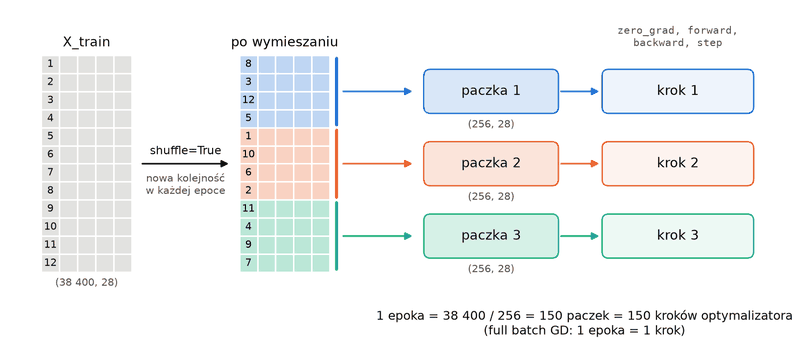

Gradient z paczki jest tylko przybliżeniem gradientu z całego zbioru, ale za to w jednej epoce wykonujemy wiele kroków, po jednym na paczkę. Przed każdą epoką dane mieszamy, żeby paczki były za każdym razem inne. Losowość gradientu z paczek pomaga też wychodzić z płaskich obszarów i płytkich minimów funkcji kosztu, a do tego działa jak lekka regularyzacja: szum w gradiencie utrudnia sieci dopasowanie się do szczegółów zbioru treningowego. Dlatego sieci trenuje się praktycznie zawsze na paczkach - dla większych modeli i zbiorów nie ma zresztą innej możliwości. Skrajny przypadek, paczki z jednym przykładem, to **stochastyczny spadek wzdłuż gradientu (stochastic gradient descent, SGD)**. Obecnie nazwą SGD określa się zwykle także trening na paczkach.

**Optymalizatory**

Zwykły krok spadku wzdłuż gradientu zależy tylko od bieżącego gradientu. Ma to wady: na płaskich obszarach kroki są bardzo małe, a w wąskich "dolinach" funkcji kosztu parametry oscylują między ich zboczami. Dwa popularne ulepszenia:
- **momentum** - krok uwzględnia też kierunek poprzednich kroków (średnią kroczącą gradientów), jak kula tocząca się z górki, która nabiera prędkości. Pomaga przejść przez płaskie fragmenty funkcji kosztu i tłumi oscylacje,
- **[Adam](https://arxiv.org/abs/1412.6980)** (*adaptive moment estimation*) - nowoczesne rozwinięcie SGD, które łączy momentum z osobną, automatycznie dobieraną wielkością kroku dla każdego parametru (parametry z dużymi gradientami dostają mniejsze kroki). Dobrze działa nawet przy niedokładnie dobranej stałej uczącej i jest obecnie domyślnym wyborem przy treningu sieci.

Więcej o optymalizacji sieci neuronowych: [film](https://www.youtube.com/watch?v=NrO20Jb-hy0).

**Przeuczenie i regularyzacja**

Sieci neuronowe mają bardzo dużo parametrów, często więcej niż przykładów treningowych, więc łatwo się **przeuczają (overfitting)**: dopasowują się do szumu w danych treningowych i gorzej działają na nowych danych. Im większa **pojemność (capacity)** sieci, tym więcej danych potrzeba, żeby się nie przeuczyła.

Przeuczenie widać na **krzywych uczenia (learning curves)**, czyli wykresach kosztu w kolejnych epokach. Po każdej epoce liczymy koszt na **zbiorze walidacyjnym (validation set)**, wydzielonym z danych treningowych - zbioru testowego do tego nie używamy, bo prowadziłoby to do wycieku danych (laboratorium 1). Typowy obraz przeuczenia: koszt treningowy cały czas spada, a koszt walidacyjny osiąga minimum i zaczyna rosnąć. Prostym rozwiązaniem jest **wczesny stop (early stopping)**, znany z boostingu w laboratorium 2: przerywamy trening, gdy koszt walidacyjny przestaje maleć, i wybieramy model z epoki z najmniejszym kosztem walidacyjnym. Lepiej jednak ograniczyć samo przeuczenie, czyli zastosować **regularyzację**.

[**Dropout**](https://jmlr.org/papers/v15/srivastava14a.html) to technika regularyzacji stworzona dla sieci neuronowych. Podczas treningu w każdym kroku zerujemy losowo każdy neuron ukryty z prawdopodobieństwem $p$:

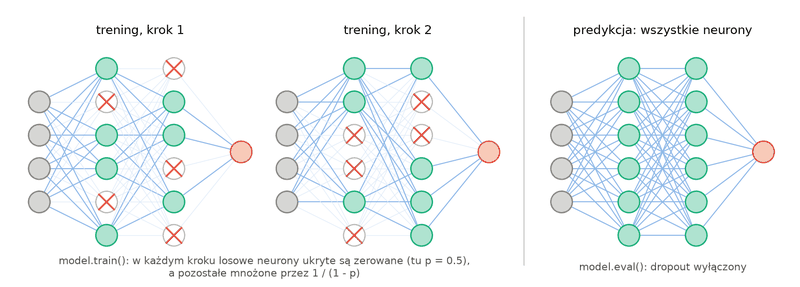

Sieć nie może więc polegać na pojedynczych neuronach i musi uczyć się cech przydatnych w wielu "przerzedzonych" wersjach sieci - podobnie jak las losowy z laboratorium 2 uśrednia wiele różnych drzew. Podczas predykcji dropout jest wyłączony. Żeby wartości trafiające do kolejnej warstwy miały w obu trybach tę samą wartość oczekiwaną, podczas treningu pozostawione neurony dzielimy przez $1-p$:

$$
\mathrm{dropout}(h)_j = \begin{cases} 0 & \text{z prawdopodobieństwem } p \\ \dfrac{h_j}{1-p} & \text{z prawdopodobieństwem } 1-p \end{cases}
$$

Typowe wartości $p$ to 0.1-0.5. Zbyt mały dropout słabo regularyzuje, a zbyt duży prowadzi do niedouczenia (underfitting). Sieci można też regularyzować tak jak modele liniowe, karą L2 za duże wagi (**weight decay**).

**Normalizacja**

Głębsza sieć może uczyć się bardziej złożonych zależności, ale trudniej ją wytrenować. Z reguły łańcuchowej gradient po wagach pierwszej warstwy to iloczyn pochodnych wszystkich kolejnych warstw. Jeśli czynniki są średnio mniejsze od 1, iloczyn maleje wykładniczo z liczbą warstw i pierwsze warstwy prawie się nie uczą - jest to problem **zanikającego gradientu (vanishing gradient)**. Jeśli czynniki są większe od 1, gradient rośnie wykładniczo (**eksplodujący gradient, exploding gradient**). Dzieje się tak m.in. wtedy, gdy wartości w kolejnych warstwach mają bardzo różne skale.

Z tego samego powodu standaryzowaliśmy cechy przed modelami liniowymi w laboratorium 2. **Warstwy normalizacji** robią to samo wewnątrz sieci: od wyjść warstwy odejmują średnią $\mu$ i dzielą je przez odchylenie standardowe $\sigma$. Wynik mnożą i przesuwają przez parametry $\gamma$ i $\beta$, uczone razem z siecią, więc sieć sama dobiera najlepszą skalę. Dwa najpopularniejsze warianty różnią się tym, po czym liczą średnią i wariancję:

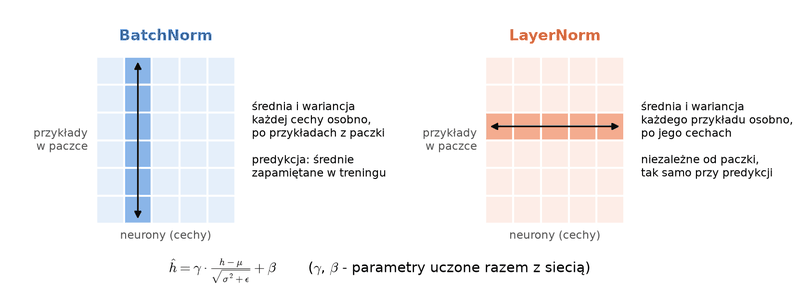

- [**BatchNorm**](https://arxiv.org/abs/1502.03167) (*batch normalization*) - osobno dla każdej cechy, po przykładach z paczki. Podczas treningu zapamiętuje średnią i wariancję z kolejnych paczek, a przy predykcji używa tych zapamiętanych wartości - tak jak dropout, działa inaczej w trybie treningu i predykcji. Jako pierwsza warstwa sieci standaryzuje cechy wejściowe, więc zastępuje `StandardScaler`, a statystyki cech są zapisane razem z modelem.
- [**LayerNorm**](https://arxiv.org/abs/1607.06450) (*layer normalization*) - osobno dla każdego przykładu, po jego cechach. Nie zależy od paczki i działa tak samo przy treningu i predykcji. Jest standardem w Transformerach (laboratorium 5).

Normalizacja stabilizuje i przyspiesza trening, a często pozwala też użyć większej stałej uczącej. BatchNorm działa dodatkowo trochę jak regularyzacja, bo statystyki z losowej paczki są zaszumione.

# Część praktyczna

## Regresja logistyczna w NumPy

Aby nabyć intuicję dotyczącą tego, jak działa propagacja wsteczna i później sieci neuronowe, rozpoczniemy od implementacji regresji logistycznej od zera w NumPy. Zbiór danych to punkty na płaszczyźnie z dwóch klas, które da się idealnie rozdzielić prostą (są **liniowo separowalne**).

Poniżej definiujemy parę funkcji pomocnicznych, których potem użyjemy. Model przekazujemy do nich jako funkcję `predict_proba`, więc zadziałają zarówno dla modeli w NumPy, jak i tych, które zdefiniujemy później w PyTorchu.

In [ ]:
from collections.abc import Callable


def make_linear_dataset(n: int = 200, seed: int = 0) -> tuple[np.ndarray, np.ndarray]:
    # points from [-3, 3]^2 labelled by the side of the line 1.5 x1 - x2 + 0.5 = 0;
    # points too close to the line are dropped, so the classes are clearly separated
    rng = np.random.default_rng(seed)
    X = rng.uniform(-3, 3, size=(3 * n, 2))
    z = X @ np.array([1.5, -1.0]) + 0.5

    keep = np.abs(z) > 0.6
    X, z = X[keep][:n], z[keep][:n]
    return X, (z > 0).astype(float)


def accuracy(
    predict_proba: Callable[[np.ndarray], np.ndarray], X: np.ndarray, y: np.ndarray
) -> float:
    return np.mean((predict_proba(X) >= 0.5) == y)


def plot_dataset(
    X: np.ndarray, y: np.ndarray, ax: plt.Axes | None = None, title: str | None = None
) -> plt.Axes:
    if ax is None:
        _, ax = plt.subplots(figsize=(4.5, 4))

    ax.scatter(
        X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=10, edgecolors="k", linewidths=0.3
    )
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_title(title or "")
    return ax


def plot_decision_boundary(
    predict_proba: Callable[[np.ndarray], np.ndarray],
    X: np.ndarray,
    y: np.ndarray,
    ax: plt.Axes | None = None,
    title: str | None = None,
) -> plt.Axes:
    if ax is None:
        _, ax = plt.subplots(figsize=(4.5, 4))

    # model predictions on a dense grid of points covering the data
    x1 = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 200)
    x2 = np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 200)
    xx1, xx2 = np.meshgrid(x1, x2)
    probs = predict_proba(np.c_[xx1.ravel(), xx2.ravel()]).reshape(xx1.shape)

    # background: probability of class 1, black line: decision boundary (p_hat = 0.5)
    ax.contourf(
        xx1, xx2, probs, levels=np.linspace(0, 1, 21), cmap="coolwarm", alpha=0.4
    )
    if probs.min() < 0.5 < probs.max():
        ax.contour(xx1, xx2, probs, levels=[0.5], colors="black", linewidths=2)

    return plot_dataset(X, y, ax=ax, title=title)


def plot_training(
    history: list[float],
    predict_proba: Callable[[np.ndarray], np.ndarray],
    X: np.ndarray,
    y: np.ndarray,
    title: str = "",
    compare: dict[str, list[float]] | None = None,
    mark_errors: bool = False,
) -> None:
    # compare: optional {label: history} of other training runs, drawn on the same learning curve plot
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

    # left: learning curve
    for label, other_history in (compare or {}).items():
        ax1.plot(other_history, label=label, alpha=0.7)
    ax1.plot(history, label=title or "training", color="black")
    ax1.set_xlabel("epoch")
    ax1.set_ylabel("cost")
    ax1.set_title(f"Learning curve - final cost {history[-1]:.3f}")
    ax1.grid(alpha=0.3)
    ax1.legend()

    # right: decision boundary of the trained model
    acc = accuracy(predict_proba, X, y)
    plot_decision_boundary(
        predict_proba, X, y, ax=ax2, title=f"{title} - accuracy {acc:.1%}"
    )
    if mark_errors:
        wrong = (predict_proba(X) >= 0.5) != y
        ax2.scatter(
            X[wrong, 0],
            X[wrong, 1],
            marker="x",
            color="black",
            s=20,
            label="wrong predictions",
        )
        ax2.legend(loc="lower left", fontsize=8)

    fig.tight_layout()
    plt.show()

In [ ]:
X_lin, y_lin = make_linear_dataset()
print("X_lin:", X_lin.shape, " y_lin:", y_lin.shape)

ax = plot_dataset(X_lin, y_lin, title="Linearly separable data")
grid_x1 = np.linspace(-3, 3, 10)
ax.plot(
    grid_x1,
    1.5 * grid_x1 + 0.5,
    "--",
    color="gray",
    label="true boundary\n(unknown to the model)",
)
ax.set_ylim(-3.3, 3.3)
ax.legend(loc="lower right", fontsize=8)
plt.show()

Model zdefiniujemy jako klasę `LogisticRegression`. Obiekt tej klasy przechowuje parametry modelu (`self.w`, `self.b`) i potrafi policzyć predykcje, czyli wykonać przejście w przód (metoda `forward`). Z bardzo podobnymi klasami spotkamy się później w PyTorchu - tam również model to klasa z parametrami i metodą `forward`.

Model liczy predykcje dla wszystkich $N$ punktów naraz, czyli dla wierszy macierzy $X$. Wzór na logity zapisujemy wtedy wektorowo, $z = X w + b$, a `X @ w + b` ma kształt $(N, 2) \cdot (2,) \to (N,)$. Funkcje NumPy, np. `np.exp`, działają element po elemencie, więc sigmoidę możemy policzyć dla całego wektora logitów naraz.

### Zadanie 1 (1 punkt)

Uzupełnij:
1. `analytical_df(x)` - pochodna funkcji $f(x) = 3x^2 - 4x + 5$ wyprowadzona na kartce.
2. `df(func, x, h)` - pochodna numeryczna **dowolnej** funkcji `func` w punkcie `x`, liczona różnicą centralną.
3. `sigmoid(z)` - funkcja sigmoidalna.
4. `LogisticRegression.__init__` - `self.w`: wektor `(n_features,)` z rozkładu normalnego o średniej 0 i odchyleniu 0.1 (`rng.normal`), `self.b`: `0.0`.
5. `LogisticRegression.forward` - prawdopodobieństwa klasy 1 dla wszystkich punktów `X` naraz, kształt `(N,)`.

Wszystkie funkcje mają działać dla tablic NumPy (element po elemencie).

In [ ]:
def f(x: float | np.ndarray) -> float | np.ndarray:
    # helper function (given)
    return 3 * x**2 - 4 * x + 5

In [ ]:
def analytical_df(x: float | np.ndarray) -> float | np.ndarray:
    # derivative of f(x) = 3x^2 - 4x + 5
    return ...


def df(
    func: Callable[[float | np.ndarray], float | np.ndarray],
    x: float | np.ndarray,
    h: float = 1e-5,
) -> float | np.ndarray:
    # numerical derivative of func at x using central difference
    return ...


def sigmoid(z: float | np.ndarray) -> float | np.ndarray:
    return ...


class LogisticRegression:
    def __init__(self, n_features: int, seed: int = 0) -> None:
        rng = np.random.default_rng(seed)
        self.w = ...  # weights, shape (n_features,)
        self.b = ...  # bias, a single number

    def forward(self, X: np.ndarray) -> np.ndarray:
        # X: (N, n_features) -> probabilities of class 1, shape (N,)
        z = ...  # logits, shape (N,)
        p_hat = ...
        return p_hat

    def predict(self, X: np.ndarray, threshold: float = 0.5) -> np.ndarray:
        # hard 0/1 predictions
        return (self.forward(X) >= threshold).astype(float)

In [ ]:
x = np.array([-2.0, 0.0, 3.0])
assert np.allclose(analytical_df(x), [-16.0, -4.0, 14.0])
assert np.allclose(df(f, x), analytical_df(x), atol=1e-5)
assert np.allclose(df(np.sin, x), np.cos(x), atol=1e-6)
assert np.allclose(sigmoid(np.array([-1.0, 0.0, 2.0])), [0.268941, 0.5, 0.880797])

model = LogisticRegression(2, seed=1)
assert np.allclose(model.w, [0.034558, 0.082162], atol=1e-5) and model.b == 0
X_example = np.array([[1.0, 2.0], [-1.0, 0.5]])
assert np.allclose(model.forward(X_example), [0.549557, 0.501631], atol=1e-5)

print("Solution is correct!")

Zwizualizujmy teraz, jaką granicę decyzyjną wyznacza model z losowo zainicjalizowanymi parametrami.

In [ ]:
model = LogisticRegression(2, seed=1)
print("parameters:  w =", model.w, "  b =", model.b)

acc = np.mean(model.predict(X_lin) == y_lin)
plot_decision_boundary(
    model.forward, X_lin, y_lin, title=f"Random parameters - accuracy {acc:.0%}"
)
plt.show()

Model wyznacza granicę decyzyjną, ale losowe parametry nie rozdzielają klas. Żeby je poprawić, potrzebujemy funkcji kosztu i jej gradientu.

### Propagacja wsteczna w kodzie

Wzory na gradient z części teoretycznej liczą sumy po punktach. W kodzie nie piszemy pętli po punktach, tylko liczymy wszystko macierzowo. Niech $\delta$, $\frac{\partial \ell}{\partial \hat p}$ i $\frac{\partial \hat p}{\partial z}$ oznaczają wektory o kształcie $(N,)$ z wartościami dla wszystkich punktów, a $\odot$ - mnożenie element po elemencie (`*` w NumPy). Wtedy:

$$
\delta = \frac{1}{N} \, \frac{\partial \ell}{\partial \hat p} \odot \frac{\partial \hat p}{\partial z}
\qquad
\nabla_w L = X^\top \delta
\qquad
\frac{\partial L}{\partial b} = \sum_{i=1}^{N} \delta_i
$$

Iloczyn $X^\top \delta$ ma kształt $(2, N) \cdot (N,) \to (2,)$, a jego $j$-ty element to dokładnie suma $\sum_{i} \delta_i \, x_{ij}$. Pochodne $\frac{\partial \ell}{\partial \hat p}$ i $\frac{\partial \hat p}{\partial z}$ moglibyśmy wyprowadzić na kartce, ale dla wygody policzymy je numerycznie funkcją `df` z Zadania 1 - funkcja kosztu punktu i sigmoida działają element po elemencie, więc `df` policzy pochodną dla wszystkich punktów naraz.

Przykład ręcznie napisanego przejścia w przód i wstecz w NumPy: [Learning PyTorch with Examples - Warm-up: numpy](https://docs.pytorch.org/tutorials/beginner/pytorch_with_examples.html#warm-up-numpy).

### Zadanie 2 (1 punkt)

Uzupełnij:
1. `bce_per_sample(p_hat, y)` - koszt każdego punktu $\ell_i$, kształt `(N,)`.
2. `bce(p_hat, y)` - średni koszt $L$.
3. `backward(model, X, y)` - gradient średniego kosztu po parametrach modelu, czyli parę `(grad_w, grad_b)`. Gradient ma zawsze kształt parametru: `grad_w` - `(2,)`, `grad_b` - liczba.
4. `train(model, X, y, lr, epochs)` - pętlę uczącą, która optymalizuje parametry modelu spadkiem wzdłuż gradientu przez `epochs` epok. Zmieniaj parametry w miejscu (przypisz nowe wartości do `model.w` i `model.b`), a do historii dopisuj koszt policzony **przed** aktualizacją, jako liczbę (`float(...)`).

Po sprawdzeniu wytrenujemy model, a `plot_training` narysuje krzywą uczenia na podstawie zwróconej historii i granicę decyzyjną.

In [ ]:
def bce_per_sample(p_hat: np.ndarray, y: np.ndarray, eps: float = 1e-12) -> np.ndarray:
    # binary cross-entropy for each point separately - (N,)
    p_hat = np.clip(p_hat, eps, 1 - eps)  # protects against log(0)
    return ...


def bce(p_hat: np.ndarray, y: np.ndarray) -> float:
    # mean binary cross-entropy - a single number
    return ...


def backward(
    model: LogisticRegression, X: np.ndarray, y: np.ndarray
) -> tuple[np.ndarray, float]:
    # gradient of the mean BCE cost w.r.t. model parameters -> (grad_w, grad_b)
    N = len(y)
    z = ...  # (N,)
    p_hat = ...  # (N,)

    # derivatives of the point cost and the sigmoid, for all points at once
    # hint: use df with a lambda function for the point cost
    dloss_dp = ...
    dp_dz = ...

    delta = ...
    grad_w = ...
    grad_b = ...
    return grad_w, grad_b


def train(
    model: LogisticRegression,
    X: np.ndarray,
    y: np.ndarray,
    lr: float = 0.5,
    epochs: int = 100,
) -> list[float]:
    # full-batch gradient descent; modifies the model in place, returns cost history (one value per epoch)
    history = []
    for epoch in range(epochs):
        p_hat = ...  # 1. forward pass
        history.append(...)  # 2. cost before the update, as float
        grad_w, grad_b = ...  # 3. gradient of the cost
        model.w = ...  # 4. update of the parameters
        model.b = ...
    return history

In [ ]:
p_hat_example, y_example = np.array([0.9, 0.2, 0.5]), np.array([1.0, 0.0, 1.0])
assert np.allclose(
    bce_per_sample(p_hat_example, y_example), [0.105361, 0.223144, 0.693147]
)
assert np.isclose(bce(p_hat_example, y_example), 0.340551)
assert (
    bce_per_sample(np.array([0.0, 1.0]), np.array([1.0, 0.0])).max() < 30
)  # no log(0)

model = LogisticRegression(2, seed=1)
grad_w, grad_b = backward(model, X_lin, y_lin)
assert grad_w.shape == (2,)
assert np.allclose(grad_w, [-0.7056, 0.5086], atol=1e-3)
assert np.isclose(grad_b, -0.1005, atol=1e-3)

history = train(model, X_lin, y_lin, lr=0.5, epochs=100)
assert len(history) == 100 and isinstance(history[0], float)
assert np.isclose(history[0], 0.7078, atol=1e-3)
assert history[-1] < history[0] / 5
assert np.all(model.predict(X_lin) == y_lin)

print("Solution is correct!")

In [ ]:
model = LogisticRegression(2, seed=1)
history = train(model, X_lin, y_lin, lr=0.5, epochs=100)
print(f"learned parameters: w = {model.w}, b = {model.b:.4f}")
plot_training(history, model.forward, X_lin, y_lin, title="NumPy")

Zobaczmy jeszcze, jak na trening wpływa stała ucząca. Po lewej trenujemy ten sam model z czterema różnymi wartościami `lr`. Po prawej spadek wzdłuż gradientu dla funkcji $f(x) = 3x^2 - 4x + 5$ z Zadania 1, startujący z $x = 3$ - rysujemy odległość od minimum $x^* = 2/3$ w kolejnych krokach.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

# left: logistic regression with different learning rates
for lr in [0.01, 0.5, 5, 50]:
    model_lr = LogisticRegression(2, seed=1)
    history_lr = train(model_lr, X_lin, y_lin, lr=lr, epochs=100)
    axes[0].plot(history_lr, lw=2, label=f"lr = {lr}")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("cost")
axes[0].set_title("Logistic regression")

# right: gradient descent on f(x), x <- x - lr * f'(x)
for lr in [0.05, 0.25, 0.34]:
    x = 3.0
    distances = []
    for step in range(30):
        distances.append(abs(x - 2 / 3))
        x = x - lr * analytical_df(x)
    axes[1].plot(distances, "o-", ms=3, lw=1.5, label=f"lr = {lr}")
axes[1].set_xlabel("step")
axes[1].set_ylabel("|x - x*|")
axes[1].set_title("Gradient descent on f(x)")

for ax in axes:
    ax.set_yscale("log")
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
plt.show()

Przy małej stałej uczącej (`lr = 0.01` po lewej, `lr = 0.05` po prawej) koszt spada bardzo powoli. Dla $f(x)$ krok `lr = 0.25` przeskakuje minimum i parametr oscyluje wokół niego, choć wciąż się do niego zbliża, a przy `lr = 0.34` każdy krok przeskakuje minimum coraz dalej - trening jest **rozbieżny**. Regresja logistyczna na naszych danych zbiega nawet przy `lr = 50`, bo dla danych liniowo separowalnych jej koszt nie ma minimum: maleje, gdy wagi rosną do nieskończoności. Dla sieci neuronowych zbyt duża stała ucząca zwykle kończy się jednak oscylacjami albo wzrostem kosztu, a zbyt mała - bardzo długim treningiem.

## PyTorch

Dotychczas pętlę uczącą pisaliśmy ręcznie w NumPy. Większość tworzenia i treningu modeli jest jednak dość schematyczna, więc w praktyce używa się frameworków. Najpopularniejszy z nich to PyTorch, udostępniony przez zespół Facebook AI Research (FAIR) w 2017 roku.

PyTorch to w uproszczeniu NumPy + GPU + [automatyczne różniczkowanie (autograd)](https://docs.pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html): gradienty, które poprzednio liczyliśmy ręcznie, policzy za nas. Najważniejsze moduły:
- [`torch`](https://docs.pytorch.org/docs/stable/torch.html) - tensory i podstawowe funkcje, np. `torch.tensor()`, `torch.zeros()`,
- [`torch.nn`](https://docs.pytorch.org/docs/stable/nn.html) - warstwy i funkcje kosztu, np. `nn.Linear`, `nn.Sigmoid`, `nn.BCELoss`,
- [`torch.optim`](https://docs.pytorch.org/docs/stable/optim.html) - optymalizatory, czyli warianty spadku wzdłuż gradientu.

Pętla ucząca ma te same kroki co nasza implementacja w NumPy:

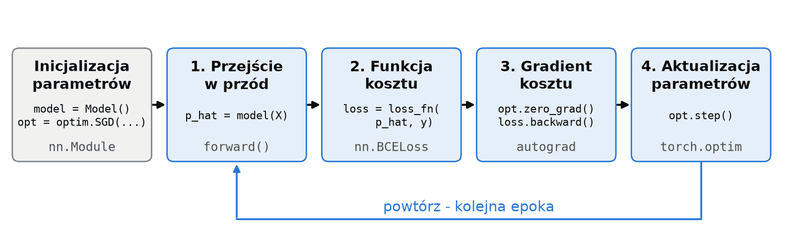

| Krok | Kod w NumPy | PyTorch |
|---|---|---|
| parametry + przejście w przód | `LogisticRegression.forward` | `nn.Module`, `nn.Linear`, `nn.Sigmoid`; wywołanie `model(X)` |
| funkcja kosztu | `bce` | `nn.BCELoss()` |
| gradient (backward pass) | `backward` | `loss.backward()` |
| aktualizacja (optymalizator) | `w - lr * grad_w` | `optimizer.step()` (+ `optimizer.zero_grad()`) |

### Tensory

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

Podstawowym obiektem w PyTorchu jest [`Tensor`](https://docs.pytorch.org/docs/stable/tensors.html), czyli wielowymiarowa tablica liczb (uogólnienie wektora i macierzy). Tensor znajduje się na pewnym urządzeniu ([`device`](https://docs.pytorch.org/docs/stable/tensor_attributes.html#torch.device)), CPU lub GPU, a przenosić między nimi trzeba explicite, metodą `.to()`. W tym laboratorium wszystko liczymy na CPU.

API tensorów jest bardzo podobne do NumPy. Dwie pułapki, na które możesz natrafić w tym laboratorium:
- **typ liczb** ([`dtype`](https://docs.pytorch.org/docs/stable/tensor_attributes.html#torch.dtype)) - NumPy domyślnie tworzy `float64`, a warstwy PyTorcha pracują na `float32`. Dane z NumPy zamieniamy przez `.float()` albo `torch.tensor(..., dtype=torch.float32)`. Dotyczy to także etykiet: `nn.BCELoss` wymaga etykiet zmiennoprzecinkowych (`0.0` i `1.0`), a nie całkowitych.
- **kształt (shape)** - model zwraca kolumnę `(N, 1)`, a etykiety mamy jako wektor `(N,)`. Funkcja kosztu wymaga tego samego kształtu, więc etykiety zamieniamy w kolumnę przez `.unsqueeze(1)` (w drugą stronę: `.squeeze(1)`).

Zamieńmy na tensory dane, na których trenowaliśmy regresję logistyczną. Więcej przykładów operacji na tensorach: [Tensors](https://docs.pytorch.org/tutorials/beginner/basics/tensorqs_tutorial.html).

In [ ]:
X_lin_t = torch.tensor(X_lin, dtype=torch.float32)  # (N, 2)
y_lin_t = torch.tensor(y_lin, dtype=torch.float32).unsqueeze(1)  # (N,) -> (N, 1)
print(
    "X_lin:", X_lin.dtype, X_lin.shape, " X_lin_t:", X_lin_t.dtype, tuple(X_lin_t.shape)
)
print(
    "y_lin:", y_lin.shape, " y_lin_t:", tuple(y_lin_t.shape), " device:", y_lin_t.device
)

print(
    "X_lin_t[:2] * 2 + 1:", X_lin_t[:2] * 2 + 1
)  # elementwise operations, as in NumPy
print("X_lin_t[:2] @ ones:", X_lin_t[:2] @ torch.ones(2))  # matrix multiplication

### Autograd

[Autograd](https://docs.pytorch.org/docs/stable/autograd.html) to mechanizm automatycznego różniczkowania w PyTorchu. Operacje na tensorach z `requires_grad=True` są zapisywane w grafie obliczeń (część teoretyczna), a każdy wynik pamięta operację, która go utworzyła (`grad_fn`). Wywołanie `.backward()` na koszcie przechodzi graf od końca z reguły łańcuchowej i zapisuje gradient w atrybucie `.grad` każdego śledzonego tensora, np. parametru modelu. Parametry warstw mają `requires_grad=True` od razu. Pochodne są liczone ze wzorów, więc są dokładne, a nie przybliżone jak w `df`. Trzeba przy tym pamiętać, że:
- gradienty się **sumują** - kolejne `.backward()` dodaje gradient do tego, który już jest w `.grad`, więc w pętli uczącej przed każdym krokiem trzeba je wyzerować,
- obliczenia, które nie są częścią treningu (predykcja, wykresy), wykonujemy w bloku [`with torch.no_grad():`](https://docs.pytorch.org/docs/stable/generated/torch.no_grad.html), co oszczędza czas i pamięć,
- `.item()` zamienia jednoelementowy tensor na liczbę Pythona, a `.detach()` odcina tensor od grafu (np. przed `.numpy()`).

Co dzieje się w środku: [micrograd](https://www.youtube.com/watch?v=VMj-3S1tku0) Andreja Karpathy'ego - autograd napisany od zera. Sprawdźmy to na funkcji $f(x) = 3x^2 - 4x + 5$ z Zadania 1:

In [ ]:
x = torch.tensor(3.0, requires_grad=True)
y = 3 * x**2 - 4 * x + 5
print("y.grad_fn:", y.grad_fn)  # y remembers the last operation that created it
y.backward()
print("x.grad:", x.grad.item(), "  analytical_df(3):", analytical_df(3.0))

y = 3 * x**2 - 4 * x + 5
y.backward()
print("after the second backward():", x.grad.item(), "<- gradients accumulate!")
x.grad.zero_()  # methods ending with _ modify the tensor in place

with torch.no_grad():
    y = 3 * x**2 - 4 * x + 5
print("in torch.no_grad(): requires_grad =", y.requires_grad)

### Modele: `nn.Module`

Model w PyTorchu to klasa dziedzicząca po [`nn.Module`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html), podobnie jak nasza `LogisticRegression` z Zadania 1. Warstwy, np. `nn.Linear`, również dziedziczą po `nn.Module`, więc modele składa się z mniejszych modułów. Rozmiary wejścia i wyjścia każdej warstwy podajemy jawnie.

| Element | Co robi |
|---|---|
| `__init__` | zaczyna od `super().__init__()`, tworzy warstwy i zapisuje je jako atrybuty - ich parametry ([`nn.Parameter`](https://docs.pytorch.org/docs/stable/generated/torch.nn.parameter.Parameter.html)) są rejestrowane automatycznie |
| `forward(X)` | przejście w przód; jedyna metoda, którą piszemy |
| `model(X)` | wywołuje `forward` |
| `model.parameters()` | wszystkie parametry modelu; przekazujemy je optymalizatorowi |

Metody `backward` nie piszemy - autograd zbuduje przejście wstecz z operacji wykonanych w `forward`. Podstawowa warstwa to [`nn.Linear(in_features, out_features)`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Linear.html), czyli nasze `X @ w + b`. Przechowuje ona wagi jako macierz `(out_features, in_features)`. Zobaczmy, jakie parametry rejestruje (`named_parameters()` zwraca je razem z nazwami):

In [ ]:
layer = nn.Linear(2, 1)
for name, param in layer.named_parameters():
    print(name, tuple(param.shape), "requires_grad =", param.requires_grad)

print("output for 3 points:", tuple(layer(torch.ones(3, 2)).shape))

### Funkcje kosztu

PyTorch zawiera większość popularnych [funkcji kosztu](https://docs.pytorch.org/docs/stable/nn.html#loss-functions), np. `nn.MSELoss` czy `nn.BCELoss`. Najczęściej używa się ich jako klas: tworzymy obiekt, np. `loss_fn = nn.BCELoss()`, i wywołujemy go jak funkcję. Istnieją też odpowiedniki w postaci funkcji w module [`torch.nn.functional`](https://docs.pytorch.org/docs/stable/nn.functional.html).

Funkcja kosztu przyjmuje argumenty w kolejności **(predykcje, etykiety)** - tak samo jak nasza `bce(p_hat, y)` - i zwraca tensor z jedną liczbą (skalar). Domyślnie jest to średnia po punktach, tak jak w `bce`. Właśnie na tym skalarze wywołujemy `.backward()`.

In [ ]:
demo_p = torch.tensor([0.9, 0.2, 0.5, 0.99])
demo_y = torch.tensor([1.0, 0.0, 1.0, 0.0])
demo_loss = nn.BCELoss()(demo_p, demo_y)  # order: (predictions, targets)
print("nn.BCELoss:", demo_loss, " shape:", tuple(demo_loss.shape))
print(f"our bce:    {bce(demo_p.numpy(), demo_y.numpy()):.4f}")

### Optymalizatory

Optymalizator (z modułu [`torch.optim`](https://docs.pytorch.org/docs/stable/optim.html)) wykonuje krok 4 pętli uczącej. Przy tworzeniu dostaje parametry modelu i stałą uczącą, a potem:
- [`optimizer.zero_grad()`](https://docs.pytorch.org/docs/stable/generated/torch.optim.Optimizer.zero_grad.html) zeruje gradienty wszystkich tych parametrów,
- [`optimizer.step()`](https://docs.pytorch.org/docs/stable/generated/torch.optim.Optimizer.step.html) aktualizuje parametry na podstawie gradientów, które `loss.backward()` zapisał w `.grad`.

[`optim.SGD`](https://docs.pytorch.org/docs/stable/generated/torch.optim.SGD.html) wykonuje dokładnie krok z naszej pętli w NumPy: $\theta \leftarrow \theta - \eta \, \nabla_\theta L$. W praktyce używa się jednak jego nowoczesnych rozwinięć, przede wszystkim [`optim.Adam`](https://docs.pytorch.org/docs/stable/generated/torch.optim.Adam.html) (część teoretyczna). Od teraz będziemy go używać we wszystkich treningach, ze stałą uczącą zwykle rzędu 0.001-0.1 - Adam sam dobiera wielkość kroku dla każdego parametru, więc jest dużo mniej wrażliwy na jej wartość.

### Zadanie 3 (1 punkt)

Uzupełnij:
1. `LogisticRegressionTorch` - regresję logistyczną jako `nn.Module`: warstwa liniowa `self.linear` z `n_features` wejściami i jednym wyjściem (logitem), a po niej sigmoida `self.activation` (`nn.Sigmoid`).
2. `train_torch` - pętlę uczącą w PyTorchu, z kosztem `nn.BCELoss`. Optymalizator jest argumentem funkcji. Nasze zbiory są tak małe, że gradient liczymy na całym zbiorze naraz - jest to po prostu jedna paczka. Do historii zapisuj `loss.item()` (zwykła liczba) - sam tensor `loss` trzymałby w pamięci cały graf obliczeń. Pierwsza linia, `model.train()`, jest podana (wyjaśnienie poniżej).

Przykład podobnej klasy: [Build the Neural Network - Define the Class](https://docs.pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html#define-the-class), a pętli: [Optimizing Model Parameters - Full Implementation](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html#full-implementation).

In [ ]:
class LogisticRegressionTorch(nn.Module):
    def __init__(self, n_features: int) -> None:
        super().__init__()
        self.linear = ...
        self.activation = ...

    def forward(self, X: torch.Tensor) -> torch.Tensor:
        # X: (N, n_features) -> probabilities of class 1, shape (N, 1)
        logits = ...
        return ...


def train_torch(
    model: nn.Module,
    optimizer: optim.Optimizer,
    X: torch.Tensor,
    y: torch.Tensor,
    epochs: int = 100,
) -> list[float]:
    # X: (N, d), y: (N, 1), both float32; returns cost history (floats, one per epoch, before the update)
    model.train()  # training mode
    loss_fn = ...
    history = []
    for epoch in range(epochs):
        ...  # 1. zero the gradients
        p_hat = ...  # 2. forward pass
        loss = ...  # 3. cost
        history.append(...)
        ...  # 4. backward pass
        ...  # 5. update of the parameters
    return history

In [ ]:
model = LogisticRegressionTorch(3)
X_example = torch.randn(4, 3)
assert isinstance(model.linear, nn.Linear) and model.linear.weight.shape == (1, 3)
assert isinstance(model.activation, nn.Sigmoid)
assert torch.allclose(model(X_example), torch.sigmoid(model.linear(X_example)))

# with plain SGD it is the same gradient descent as in NumPy (Task 2), from the same starting point
model = LogisticRegressionTorch(2)
np_model = LogisticRegression(2)
np_model.w = model.linear.weight.detach().numpy().ravel().astype(float)
np_model.b = model.linear.bias.item()
history = train_torch(
    model, optim.SGD(model.parameters(), lr=0.5), X_lin_t, y_lin_t, epochs=100
)
history_np = train(np_model, X_lin, y_lin, lr=0.5, epochs=100)
assert len(history) == 100 and isinstance(history[0], float)
# if it fails, check if you zero the gradients
assert np.allclose(history, history_np, atol=1e-3)

print("Solution is correct!")

Do predykcji przełączamy model w tryb ewaluacji ([`model.eval()`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.eval)) i wyłączamy gradienty (`torch.no_grad()`). Tryb ma znaczenie dla warstw, które działają inaczej podczas treningu (np. dropout albo batch norm), dlatego pętla ucząca zaczyna się od [`model.train()`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.train). Funkcja `torch_proba` robi to za nas i zwraca wynik jako tablicę NumPy dla naszych funkcji rysujących.

Wytrenujmy regresję logistyczną Adamem i porównajmy ją z treningiem w NumPy. Krzywe różnią się też na starcie, bo modele zaczynają z innych losowych parametrów.

In [ ]:
def torch_proba(model: nn.Module) -> Callable[[np.ndarray], np.ndarray]:
    def predict_proba(X_np: np.ndarray) -> np.ndarray:
        model.eval()
        with torch.no_grad():
            return model(torch.tensor(X_np, dtype=torch.float32)).squeeze(1).numpy()

    return predict_proba


torch.manual_seed(0)
logreg_lin = LogisticRegressionTorch(2)
optimizer = optim.Adam(logreg_lin.parameters(), lr=0.1)
history_torch = train_torch(logreg_lin, optimizer, X_lin_t, y_lin_t, epochs=100)
plot_training(
    history_torch,
    torch_proba(logreg_lin),
    X_lin,
    y_lin,
    title="PyTorch",
    compare={"NumPy": history},
)

## Sieć neuronowa MLP

### Zbiór moons

[`make_moons`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_moons.html) generuje dwa przeplatające się półkola - klas nie da się rozdzielić prostą. Trenujemy na nim tę samą regresję logistyczną (krzyżyki to błędne predykcje).

In [ ]:
from sklearn.datasets import make_moons

X_moons, y_moons = make_moons(n_samples=1000, noise=0.1, random_state=4)
X_moons_t = torch.tensor(X_moons, dtype=torch.float32)  # (N, 2)
y_moons_t = torch.tensor(y_moons, dtype=torch.float32).unsqueeze(1)  # (N, 1)

torch.manual_seed(0)
logreg_moons = LogisticRegressionTorch(2)
optimizer = optim.Adam(logreg_moons.parameters(), lr=0.1)
history_logreg = train_torch(logreg_moons, optimizer, X_moons_t, y_moons_t, epochs=1000)
plot_training(
    history_logreg,
    torch_proba(logreg_moons),
    X_moons,
    y_moons,
    title="Logistic regression",
    mark_errors=True,
)

Koszt przestaje maleć, a granica decyzyjna regresji logistycznej to zawsze prosta - dłuższy trening ani inna stała ucząca tego nie zmienią. Potrzebujemy sieci MLP z nieliniową warstwą ukrytą.

### MLP w PyTorchu

Nasza sieć ma warstwę ukrytą z 3 neuronami z aktywacją $\tanh$. Warstwy łączymy kontenerem [`nn.Sequential`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Sequential.html), który wywołuje je po kolei (przykład: [Build the Neural Network - nn.Sequential](https://docs.pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html#nn-sequential)). Nie używamy zwykłej listy Pythona, bo parametry warstw z listy nie trafiłyby do `model.parameters()`.

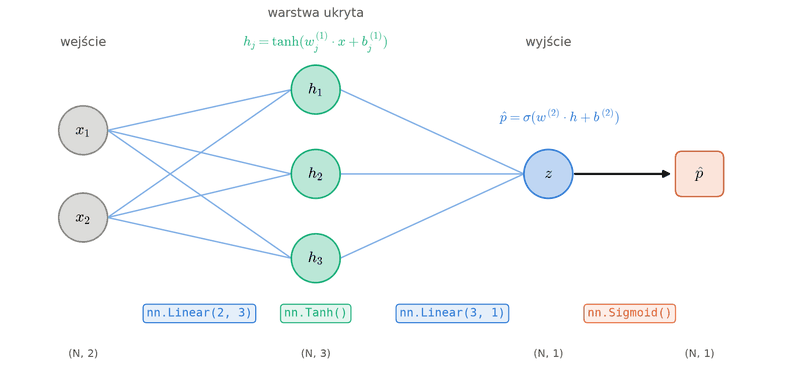

### Zadanie 4 (0.5 punktu)

Uzupełnij `MoonMLP`:
- w `self.layers` utwórz `nn.Sequential` z warstwami jak na schemacie powyżej
- `hidden_size` neuronów ukrytych
- wywołaj go w `forward`

Sieć trenujemy funkcją `train_torch`, ale z optymalizatorem `optim.Adam`.

In [ ]:
class MoonMLP(nn.Module):
    def __init__(self, hidden_size: int = 3) -> None:
        super().__init__()
        self.layers = ...

    def forward(self, X: torch.Tensor) -> torch.Tensor:
        # X: (N, 2) -> probabilities of class 1, shape (N, 1)
        ...

In [ ]:
# the network's cost is not convex - the result depends on the random start
torch.manual_seed(0)
mlp = MoonMLP(hidden_size=3)
optimizer = optim.Adam(mlp.parameters(), lr=0.03)
history_mlp = train_torch(mlp, optimizer, X_moons_t, y_moons_t, epochs=1000)

plot_training(
    history_mlp,
    torch_proba(mlp),
    X_moons,
    y_moons,
    title="MLP",
    compare={"logistic regression": history_logreg},
)

In [ ]:
layer_types = [type(layer) for layer in mlp.layers]
assert layer_types == [nn.Linear, nn.Tanh, nn.Linear, nn.Sigmoid]
assert mlp.layers[0].out_features == 3
assert MoonMLP(hidden_size=5).layers[0].out_features == 5
assert mlp(torch.randn(5, 2)).shape == (5, 1)
assert accuracy(torch_proba(mlp), X_moons, y_moons) > 0.95

print("Solution is correct!")

Przez pierwsze epoki koszt MLP stoi na poziomie regresji logistycznej (sieć zachowuje się jak model liniowy), a potem gwałtownie spada, gdy sieć "odkrywa", jak zgiąć granicę. Takie **plateau** są typowe przy uczeniu sieci. Dokładność liczymy tu na zbiorze treningowym - w praktyce ocenia się model na osobnym zbiorze testowym.

Na plateau dobrze widać różnicę między optymalizatorami. Poniżej trenujemy tę samą sieć zwykłym SGD, SGD z momentum (`optim.SGD(..., momentum=0.9)`) i Adamem, za każdym razem z trzech różnych losowych startów.

In [ ]:
optimizers = {
    "SGD, lr = 0.1": lambda params: optim.SGD(params, lr=0.1),
    "SGD with momentum, lr = 0.1": lambda params: optim.SGD(
        params, lr=0.1, momentum=0.9
    ),
    "Adam, lr = 0.03": lambda params: optim.Adam(params, lr=0.03),
}

plt.figure(figsize=(7, 3.8))
for color, (name, make_optimizer) in zip(["C0", "C1", "C2"], optimizers.items()):
    accs = []
    for seed in range(3):  # the same network from three different random starts
        torch.manual_seed(seed)
        net = MoonMLP(hidden_size=3)
        hist = train_torch(
            net, make_optimizer(net.parameters()), X_moons_t, y_moons_t, epochs=1000
        )
        plt.plot(hist, color=color, lw=1, label=name if seed == 0 else None)
        accs.append(accuracy(torch_proba(net), X_moons, y_moons))
    print(f"{name}: accuracy {', '.join(f'{acc:.1%}' for acc in accs)}")

plt.xlabel("epoch")
plt.ylabel("cost")
plt.title("Same network, different optimizers (3 random starts)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Zwykłe SGD w 1000 epok nie schodzi z plateau i zostaje na poziomie regresji logistycznej. SGD z momentum wychodzi z niego później i nie przy każdym starcie. Adam wychodzi najwcześniej i za każdym razem.

Zajrzyjmy teraz do środka sieci. Po lewej proste, na których neurony ukryte zmieniają znak - z tych "cięć" sieć składa granicę. Po prawej punkty w przestrzeni ukrytej $h$: tu klasy rozdziela już **płaszczyzna** ostatniej warstwy.

In [ ]:
# parameters and hidden representation of the trained network
W_h = mlp.layers[0].weight.detach().numpy()  # (3, 2)
b_h = mlp.layers[0].bias.detach().numpy()  # (3,)
W_out = mlp.layers[2].weight.detach().numpy().ravel()  # (3,)
b_out = mlp.layers[2].bias.item()
with torch.no_grad():
    H = mlp.layers[1](mlp.layers[0](X_moons_t)).numpy()  # (N, 3)

fig = plt.figure(figsize=(10, 4.2))

# left: lines where the hidden neurons change sign
ax1 = fig.add_subplot(1, 2, 1)
plot_decision_boundary(
    torch_proba(mlp), X_moons, y_moons, ax=ax1, title="Hidden neuron lines"
)
x1 = np.linspace(X_moons[:, 0].min() - 0.5, X_moons[:, 0].max() + 0.5, 50)
for j in range(len(b_h)):
    ax1.plot(
        x1,
        -(W_h[j, 0] * x1 + b_h[j]) / W_h[j, 1],
        "--",
        lw=2,
        label=f"neuron $h_{j + 1}$",
    )
ax1.set_ylim(X_moons[:, 1].min() - 0.5, X_moons[:, 1].max() + 0.5)
ax1.legend(loc="lower left", fontsize=8)

# right: points in the hidden space and the plane of the output layer (W_out . h + b_out = 0)
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.scatter(
    H[:, 0],
    H[:, 1],
    H[:, 2],
    c=y_moons,
    cmap="coolwarm",
    s=6,
    edgecolors="k",
    linewidths=0.2,
)
g1, g2 = np.meshgrid(np.linspace(-1, 1, 20), np.linspace(-1, 1, 20))
plane = -(W_out[0] * g1 + W_out[1] * g2 + b_out) / W_out[2]
plane[np.abs(plane) > 1] = np.nan
ax2.plot_surface(g1, g2, plane, alpha=0.3, color="gray")

ax2.set_xlabel("$h_1$")
ax2.set_ylabel("$h_2$")
ax2.set_zlabel("$h_3$")
ax2.set_title("Hidden space")
ax2.view_init(elev=15, azim=-130)  # try other angles, e.g. azim=-60

fig.tight_layout()
plt.show()

Na koniec porównajmy kilka architektur: sieci z 1, 2 i 3 neuronami ukrytymi oraz sieć z 8 neuronami bez nieliniowości (`nn.Identity()` zamiast `nn.Tanh()`).

In [ ]:
def build_and_train(model: nn.Module, epochs: int = 1000) -> nn.Module:
    optimizer = optim.Adam(model.parameters(), lr=0.03)
    train_torch(model, optimizer, X_moons_t, y_moons_t, epochs=epochs)
    return model


torch.manual_seed(0)
models = {
    f"{h} neuron(s), tanh": build_and_train(MoonMLP(hidden_size=h)) for h in (1, 2, 3)
}
models["8 neurons, no activation"] = build_and_train(
    nn.Sequential(nn.Linear(2, 8), nn.Identity(), nn.Linear(8, 1), nn.Sigmoid())
)

fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, (name, net) in zip(axes, models.items()):
    acc = accuracy(torch_proba(net), X_moons, y_moons)
    plot_decision_boundary(
        torch_proba(net), X_moons, y_moons, ax=ax, title=f"{name}: {acc:.1%}"
    )
fig.tight_layout()
plt.show()

Sieć bez aktywacji wyznacza prostą mimo 8 neuronów, bo złożenie funkcji liniowych jest funkcją liniową. Sieć z jednym neuronem ukrytym też wyznacza prostą: jej wyjście zależy od $x$ tylko przez jedną kombinację liniową $w^\top x + b$, a $\tanh$ i sigmoida tylko ją monotonicznie przekształcają.

## Sieć neuronowa na danych tabelarycznych

Teraz wytrenujemy większą sieć MLP na prawdziwych **danych tabelarycznych (tabular data)**, takich jak w laboratoriach 1 i 2: każdy wiersz to jeden przykład, a każda kolumna to jedna cecha. Użyjemy w praktyce treningu na paczkach danych, wczesnego stopu, dropoutu i normalizacji, a wyniki porównamy z modelami z laboratorium 2.

### Zbiór danych HIGGS

Wykorzystamy zbiór [HIGGS](https://archive.ics.uci.edu/dataset/280/higgs) (Baldi, Sadowski, Whiteson, licencja CC BY 4.0). Każdy wiersz opisuje jedno zderzenie cząstek w akceleratorze, zasymulowane komputerowo. W części zderzeń powstaje poszukiwana cząstka, bozon Higgsa (klasa 1, **sygnał**), a w pozostałych zachodzą zwykłe procesy, które zostawiają w detektorze bardzo podobne ślady (klasa 0, **tło**). Zadaniem jest klasyfikacja binarna: odróżnienie sygnału od tła na podstawie pomiarów. 21 cech to bezpośrednie pomiary z detektora (energie i kierunki zarejestrowanych cząstek), a 7 cech o nazwach `m_...` obliczyli z nich eksperci - to przykład ręcznej inżynierii cech. Do rozwiązania zadań fizyka nie jest potrzebna, dla nas to po prostu 28 cech liczbowych (opis w pliku [higgs_description.txt](higgs_description.txt)). Używamy losowej próbki 60 tysięcy z 11 milionów wierszy.

Dane są zapisane w formacie [Apache Parquet](https://parquet.apache.org/) zamiast CSV. Jest to **binarny, kolumnowy format z kompresją**: wartości każdej kolumny są przechowywane obok siebie i kompresowane (tutaj algorytmem ZSTD), a plik zapamiętuje typy kolumn. Dzięki temu jest kilka razy mniejszy od nieskompresowanego CSV, wczytuje się dużo szybciej, nie trzeba zgadywać typów danych, a można też wczytać tylko wybrane kolumny. Parquet jest obecnie standardem dla zbiorów danych w uczeniu maszynowym (np. na [Hugging Face Hub](https://huggingface.co/datasets)) i w przetwarzaniu dużych danych (m.in. Spark, Polars, DuckDB, BigQuery). W Pandas wczytujemy go funkcją `pd.read_parquet()`, która korzysta z biblioteki PyArrow. Minusem jest to, że pliku nie da się podejrzeć w edytorze tekstu ani w arkuszu kalkulacyjnym.

In [ ]:
df = pd.read_parquet("higgs_data.parquet")
y = df.pop("class")

print(
    f"Samples: {len(df)}, features: {df.shape[1]}, missing values: {df.isna().sum().sum()}"
)
print(f"Signal (class 1): {y.mean():.1%}")
df.head()

Wszystkie cechy są liczbowe, nie ma wartości brakujących, a klasy są prawie zbalansowane. Modele będziemy oceniać za pomocą AUROC (laboratorium 2). Zobaczmy rozkłady trzech cech osobno dla obu klas.

In [ ]:
BLUE, GRAY, RED = "#2a78d6", "#8a8984", "#e34948"

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, column in zip(axes, ["m_bb", "m_wwbb", "jet1phi"]):
    bins = np.linspace(df[column].quantile(0.001), df[column].quantile(0.995), 50)
    for label, color, name in [(0, BLUE, "background (0)"), (1, RED, "signal (1)")]:
        ax.hist(
            df.loc[y == label, column],
            bins=bins,
            density=True,
            histtype="step",
            lw=2,
            color=color,
            label=name,
        )
    ax.set_title(column)
    ax.set_xlabel("feature value")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("density")
axes[0].legend()
fig.tight_layout()
plt.show()

Histogramy pokazują rozkład wartości cechy osobno dla każdej klasy. Są znormalizowane (`density=True`), tzn. pole pod każdą krzywą wynosi 1, więc klasy można porównywać niezależnie od liczby przykładów:
- `m_bb` i `m_wwbb` to cechy obliczone przez ekspertów. Sygnał ma na nich wyraźny pik, którego nie ma tło, więc niosą sporo informacji - `m_bb` więcej niż `m_wwbb`,
- `jet1phi` to kąt zmierzony przez detektor. Ma taki sam rozkład w obu klasach, więc sam nie niesie żadnej informacji.

Nawet dla najlepszej cechy, `m_bb`, rozkłady mocno na siebie nachodzą, więc żaden próg na jednej cesze nie rozdzieli klas. Informacja jest w **kombinacjach** wielu cech naraz, więc potrzebujemy modelu nieliniowego.

### Zbiór walidacyjny

Po każdej epoce chcemy sprawdzać koszt na zbiorze walidacyjnym, więc dzielimy dane na trzy części w proporcjach 64% / 16% / 20% (trening / walidacja / test), ze stratyfikacją.

Dla sieci ważna jest skala cech: cechy o dużych wartościach dominowałyby sumy ważone w neuronach i gradienty, a wszystkie wagi startują z wartości w tej samej skali. Nie używamy jednak `StandardScaler` - cechy wystandaryzuje pierwsza warstwa sieci, BatchNorm (część teoretyczna). Dane zamieniamy na tensory `float32`, a etykiety na kolumnę `(N, 1)`.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df, y, test_size=0.2, stratify=y, random_state=0
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=0
)


def to_tensors(X: pd.DataFrame, y: pd.Series) -> tuple[torch.Tensor, torch.Tensor]:
    X_t = torch.tensor(X.to_numpy(), dtype=torch.float32)  # (N, n_features)
    y_t = torch.tensor(y.to_numpy(), dtype=torch.float32).unsqueeze(1)  # (N, 1)
    return X_t, y_t


X_train_t, y_train_t = to_tensors(X_train, y_train)
X_val_t, y_val_t = to_tensors(X_val, y_val)
X_test_t, y_test_t = to_tensors(X_test, y_test)
n_features = X_train_t.shape[1]

print(
    f"train: {tuple(X_train_t.shape)}, validation: {tuple(X_val_t.shape)}, test: {tuple(X_test_t.shape)}"
)

### Modele odniesienia

Zanim zaczniemy trenować sieć, sprawdźmy dwa modele z laboratorium 2, z domyślnymi hiperparametrami:
- **regresję logistyczną** - model liniowy,
- **Random Forest** - 300 drzew,

Random Forest nie potrzebuje skalowania cech, a regresję logistyczną łączymy ze `StandardScaler` w pipeline. W słowniku `results` zapisujemy AUROC na zbiorze treningowym, walidacyjnym i testowym. Funkcja `plot_results` narysuje wyniki wszystkich modeli - wywołamy ją, gdy będzie już co porównywać.

In [ ]:
from sklearn.base import BaseEstimator
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression as LogisticRegressionSklearn
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

BASELINES = ["Logistic regression", "Random Forest"]
results = {}


def evaluate_sklearn(
    model: BaseEstimator,
    X_train: pd.DataFrame,
    X_val: pd.DataFrame,
    X_test: pd.DataFrame,
    y_train: pd.Series,
    y_val: pd.Series,
    y_test: pd.Series,
) -> dict[str, float]:
    # AUROC on the three splits
    return {
        "train_auroc": roc_auc_score(y_train, model.predict_proba(X_train)[:, 1]),
        "val_auroc": roc_auc_score(y_val, model.predict_proba(X_val)[:, 1]),
        "test_auroc": roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]),
    }


def plot_results(
    results: dict[str, dict[str, float]], xlim: tuple[float, float] = (0.5, 1.0)
) -> None:
    # test AUROC of all models; bars start at the left end of xlim
    names = list(results)[::-1]  # the first model at the top
    scores = np.array([results[name]["test_auroc"] for name in names])
    colors = [GRAY if name in BASELINES else BLUE for name in names]

    fig, ax = plt.subplots(figsize=(8, 0.4 * len(names) + 1.2))
    ax.barh(names, scores - xlim[0], left=xlim[0], height=0.6, color=colors)
    for i, score in enumerate(scores):
        ax.text(score + 0.002, i, f"{score:.3f}", va="center", fontsize=9)
    ax.set_xlim(*xlim)
    ax.set_xlabel("test AUROC")
    ax.set_title("Neural networks (blue) and reference models (gray)")
    ax.grid(axis="x", alpha=0.3)
    plt.show()


splits = (X_train, X_val, X_test, y_train, y_val, y_test)
baselines = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegressionSklearn()),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, n_jobs=-1, random_state=0
    ),
}
for name, model in baselines.items():
    model.fit(X_train, y_train)
    results[name] = evaluate_sklearn(model, *splits)

pd.DataFrame(results).T.round(3)

Regresja logistyczna jest wyraźnie słabsza, bo model liniowy nie wykorzysta kombinacji cech. Random Forest osiąga dużo lepszy wynik bez doboru hiperparametrów - to poprzeczka dla naszej sieci. Zwróć uwagę na AUROC treningowe lasu losowego: jest równe prawie 1, bo głębokie drzewa dopasowują się do danych treningowych.

### `Dataset` i `DataLoader`

Sieć będziemy trenować na paczkach danych (*minibatch*, część teoretyczna). W PyTorchu paczki tworzą dwie klasy z modułu [`torch.utils.data`](https://docs.pytorch.org/docs/stable/data.html):
- `Dataset` - zbiór danych, czyli klasa dziedzicząca po `Dataset` z metodami `__len__()` (liczba przykładów) i `__getitem__(i)` ($i$-ty przykład, u nas para `(X[i], y[i])`). Dla dużych zbiorów, np. obrazów, `__getitem__` może wczytywać przykład z dysku dopiero wtedy, gdy jest potrzebny. PyTorch ma też gotową klasę `TensorDataset` dla danych, które są już tensorami,
- `DataLoader(dataset, batch_size, shuffle=True)` - pobiera z `dataset` po `batch_size` przykładów i skleja je w paczki. Iterujemy po nim pętlą `for X_batch, y_batch in loader:`, a `shuffle=True` miesza dane przed każdą epoką.

Przykład: [Creating a Custom Dataset](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html#creating-a-custom-dataset-for-your-files).

### Koszt liczony z logitów

W praktyce sieć zwraca zwykle sam **logit** $z$, bez sigmoidy, a sigmoidę zawiera funkcja kosztu [`nn.BCEWithLogitsLoss`](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html). Wynik jest matematycznie ten sam co dla `nn.BCELoss`, ale obliczenia są stabilniejsze numerycznie: dla dużych $|z|$ sigmoida w typie `float32` zwraca dokładnie 0 albo 1, a wtedy w BCE pojawia się $\log(0)$:

In [ ]:
z = torch.tensor([[20.0]])  # a very confident logit...
target = torch.tensor([[0.0]])  # ...but the true class is 0

print("sigmoid(z) in float32:  ", torch.sigmoid(z).item())
print("BCELoss(sigmoid(z)):    ", nn.BCELoss()(torch.sigmoid(z), target).item())
print(
    "BCEWithLogitsLoss(z):   ",
    nn.BCEWithLogitsLoss()(z, target).item(),
    " <- correct: -log(1 - sigmoid(20)) = 20",
)

`nn.BCELoss` obcina $\log(0)$ do $-100$, więc koszt jest błędny. Prawdopodobieństwa przy predykcji liczymy więc sami: `torch.sigmoid(model(X))`.

### Zadanie 5 (1 punkt)

Uzupełnij:
- klasę `TabularDataset` (`X` - tensor cech `(N, d)`, `y` - tensor etykiet `(N, 1)`),
- `train_loader` - `DataLoader` dla zbioru treningowego (`X_train_t`, `y_train_t`) z paczkami po 256 przykładów, mieszający dane przed każdą epoką,
- `train_epoch` - jedną epokę treningu na paczkach: kroki z `train_torch` (Zadanie 3) wykonujemy dla każdej paczki z `loader`. Funkcja zwraca średni koszt w epoce: sumę `loss.item() * len(X_batch)` (ostatnia paczka może być mniejsza) podzieloną przez liczbę przykładów `len(loader.dataset)`.

In [ ]:
from torch.utils.data import DataLoader, Dataset


class TabularDataset(Dataset):
    def __init__(self, X: torch.Tensor, y: torch.Tensor) -> None:
        self.X = X  # features, shape (N, d)
        self.y = y  # labels, shape (N, 1)

    def __len__(self) -> int:
        # number of examples
        return ...

    def __getitem__(self, i: int) -> tuple[torch.Tensor, torch.Tensor]:
        # i-th example: a pair (features, label)
        return ...


train_loader = ...


def train_epoch(
    model: nn.Module, loader: DataLoader, loss_fn: nn.Module, optimizer: optim.Optimizer
) -> float:
    # one epoch of minibatch training; returns the mean training cost (float)
    model.train()
    total_loss = 0.0
    for X_batch, y_batch in loader:
        # zero the gradients, forward pass, cost, backward pass, update of the parameters
        ...
        total_loss += ...
    return total_loss / len(loader.dataset)

In [ ]:
from torch.utils.data import RandomSampler

X_example = torch.arange(30.0).reshape(10, 3)
y_example = torch.arange(10.0).unsqueeze(1)
dataset = TabularDataset(X_example, y_example)
assert len(dataset) == 10
assert torch.equal(dataset[4][0], X_example[4])
assert torch.equal(dataset[4][1], y_example[4])
X_batch, y_batch = next(iter(DataLoader(dataset, batch_size=4)))
assert X_batch.shape == (4, 3) and y_batch.shape == (4, 1)

assert isinstance(train_loader.dataset, TabularDataset)
assert len(train_loader.dataset) == 38400
assert train_loader.batch_size == 256
assert isinstance(train_loader.sampler, RandomSampler)  # shuffle=True

# one epoch on a small deterministic example: 5 batches, the last one with 6 points
X_example = torch.randn(70, 3, generator=torch.Generator().manual_seed(0))
y_example = (X_example[:, :1] > 0).float()
loader_example = DataLoader(TabularDataset(X_example, y_example), batch_size=16)
torch.manual_seed(0)
model = nn.Linear(3, 1)
epoch_loss = train_epoch(
    model, loader_example, nn.BCEWithLogitsLoss(), optim.SGD(model.parameters(), lr=0.5)
)
assert isinstance(epoch_loss, float)
assert abs(epoch_loss - 0.6496) < 1e-3
# if it fails, check if you zero the gradients and make one step per batch
assert torch.allclose(
    model.weight, torch.tensor([[0.7037, 0.2628, -0.2831]]), atol=1e-3
)

print("Solution is correct!")

In [ ]:
X_batch, y_batch = next(iter(train_loader))  # the first batch
print("one batch:", tuple(X_batch.shape), tuple(y_batch.shape))
print("batches (optimizer steps) per epoch:", len(train_loader))

### Sieć MLP dla danych tabelarycznych

Sieć dla danych tabelarycznych zaczyna się od warstwy [`nn.BatchNorm1d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.BatchNorm1d.html), która standaryzuje cechy wejściowe. Potem ma kilka warstw ukrytych z tą samą liczbą neuronów i aktywacją ReLU. Warstwa wyjściowa zwraca jeden logit, bez sigmoidy:

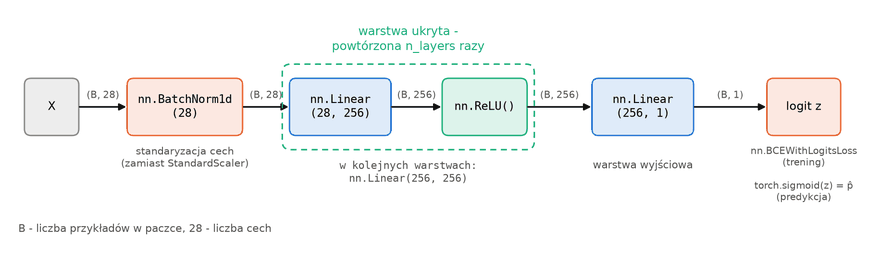

Liczba warstw jest parametrem, więc warstwy tworzymy w pętli i dopisujemy do listy `layers`, a na końcu przekazujemy je do `nn.Sequential(*layers)` - gwiazdka rozpakowuje listę w osobne argumenty.

Do treningu potrzebujemy jeszcze pętli uczącej, która po każdej epoce liczy też koszt na zbiorze walidacyjnym. Oba koszty zapisujemy w historii, żeby narysować krzywe uczenia. Koszt walidacyjny liczymy w trybie ewaluacji (`model.eval()`) i bez śledzenia gradientów (`torch.no_grad()`), tak jak przy predykcji.

### Zadanie 6 (1 punkt)

Uzupełnij:
- `TabularMLP` - sieć jak na schemacie powyżej: `nn.BatchNorm1d(n_features)`, `n_layers` warstw ukrytych (`nn.Linear` z `hidden_size` neuronami i `nn.ReLU()`) i warstwę wyjściową `nn.Linear` z jednym wyjściem,
- `fit` - pętlę uczącą z walidacją. W każdej z `epochs` epok wykonaj epokę treningu funkcją `train_epoch` z Zadania 5 (z kosztem `loss_fn`) i dopisz zwrócony koszt do `history["train_loss"]`, a potem policz koszt modelu na zbiorze walidacyjnym `(X_val, y_val)` i dopisz go do `history["val_loss"]` jako liczbę (`.item()`).

In [ ]:
loss_fn = nn.BCEWithLogitsLoss()


class TabularMLP(nn.Module):
    def __init__(
        self, n_features: int, hidden_size: int = 256, n_layers: int = 3
    ) -> None:
        super().__init__()
        # standardization of the input features
        layers = ...
        in_size = n_features
        for _ in range(n_layers):
            # hidden layer: linear layer and activation
            ...
        # output layer: one logit, no sigmoid
        ...
        self.layers = nn.Sequential(*layers)

    def forward(self, X: torch.Tensor) -> torch.Tensor:
        # X: (N, n_features) -> logits, shape (N, 1)
        ...


def fit(
    model: nn.Module,
    optimizer: optim.Optimizer,
    train_loader: DataLoader,
    X_val: torch.Tensor,
    y_val: torch.Tensor,
    epochs: int,
) -> dict[str, list[float]]:
    # training with validation after every epoch; returns the training and validation cost of every epoch
    history = {"train_loss": [], "val_loss": []}
    for _ in range(epochs):
        # training
        train_loss = ...
        history["train_loss"].append(train_loss)

        # validation
        ...
        val_loss = ...
        history["val_loss"].append(val_loss)
    return history

In [ ]:
model = TabularMLP(5, hidden_size=8, n_layers=2)
layer_types = [type(layer) for layer in model.layers]
assert layer_types == [nn.BatchNorm1d] + [nn.Linear, nn.ReLU] * 2 + [nn.Linear]
linear_sizes = [
    (layer.in_features, layer.out_features)
    for layer in model.layers
    if isinstance(layer, nn.Linear)
]
assert linear_sizes == [(5, 8), (8, 8), (8, 1)]
assert model.layers[0].num_features == 5
assert model(torch.randn(4, 5)).shape == (4, 1)

# training on a small example; validation cost has to be computed in evaluation mode (here: without dropout)
generator = torch.Generator().manual_seed(0)
X_example = torch.randn(64, 3, generator=generator)
X_val_example = torch.randn(32, 3, generator=generator)
y_example = (X_example[:, :1] > 0).float()
y_val_example = (X_val_example[:, :1] > 0).float()
loader_example = DataLoader(TabularDataset(X_example, y_example), batch_size=16)
model = nn.Sequential(nn.Linear(3, 8), nn.Dropout(0.5), nn.Linear(8, 1))
history = fit(
    model,
    optim.SGD(model.parameters(), lr=0.5),
    loader_example,
    X_val_example,
    y_val_example,
    epochs=3,
)
assert set(history) == {"train_loss", "val_loss"}
assert len(history["train_loss"]) == 3 and len(history["val_loss"]) == 3
assert all(
    isinstance(value, float) for value in history["train_loss"] + history["val_loss"]
)
assert history["train_loss"][-1] < history["train_loss"][0]
model.eval()
with torch.no_grad():
    val_loss = loss_fn(model(X_val_example), y_val_example).item()
assert abs(history["val_loss"][-1] - val_loss) < 1e-5

print("Solution is correct!")

Funkcje pomocnicze do eksperymentów:
- `predict_proba(model, X)` zwraca prawdopodobieństwa klasy 1 jako tablicę NumPy,
- `evaluate_torch(model, ...)` liczy AUROC sieci na trzech zbiorach, tak jak `evaluate_sklearn` dla modeli scikit-learn,
- `plot_learning_curves(histories, names)` rysuje krzywe uczenia podanych eksperymentów na jednym wykresie: koszt walidacyjny linią ciągłą, a treningowy przerywaną. Kropka oznacza epokę z najmniejszym kosztem walidacyjnym.

In [ ]:
histories = {}
splits_t = (X_train_t, X_val_t, X_test_t, y_train, y_val, y_test)


def predict_proba(model: nn.Module, X: torch.Tensor) -> np.ndarray:
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(X)).squeeze(1).numpy()


def evaluate_torch(
    model: nn.Module,
    X_train: torch.Tensor,
    X_val: torch.Tensor,
    X_test: torch.Tensor,
    y_train: pd.Series,
    y_val: pd.Series,
    y_test: pd.Series,
) -> dict[str, float]:
    # AUROC on the three splits; X_* are tensors
    return {
        "train_auroc": roc_auc_score(y_train, predict_proba(model, X_train)),
        "val_auroc": roc_auc_score(y_val, predict_proba(model, X_val)),
        "test_auroc": roc_auc_score(y_test, predict_proba(model, X_test)),
    }


def plot_learning_curves(
    histories: dict[str, dict[str, list[float]]], names: list[str]
) -> None:
    # one color per experiment; dots mark the lowest validation cost
    fig, ax = plt.subplots(figsize=(8, 4))
    for i, name in enumerate(names):
        history, color = histories[name], f"C{i}"
        epochs = np.arange(1, len(history["val_loss"]) + 1)
        ax.plot(
            epochs, history["val_loss"], color=color, lw=2, label=f"{name}: validation"
        )
        ax.plot(
            epochs,
            history["train_loss"],
            color=color,
            lw=1.5,
            ls="--",
            label=f"{name}: training",
        )
        best = int(np.argmin(history["val_loss"]))
        ax.scatter(best + 1, history["val_loss"][best], color=color, s=40, zorder=3)
    ax.set_xlabel("epoch")
    ax.set_ylabel("cost (BCE)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
    plt.show()

Wytrenujmy `TabularMLP` z domyślnymi rozmiarami (3 warstwy ukryte po 256 neuronów) optymalizatorem Adam ze stałą uczącą 0.003, przez 40 epok:

In [ ]:
torch.manual_seed(0)
mlp = TabularMLP(n_features)
print("parameters:", sum(p.numel() for p in mlp.parameters()))
optimizer = optim.Adam(mlp.parameters(), lr=3e-3)
histories["MLP"] = fit(mlp, optimizer, train_loader, X_val_t, y_val_t, epochs=40)
results["MLP"] = evaluate_torch(mlp, *splits_t)
print(f"test AUROC: {results['MLP']['test_auroc']:.4f}")
plot_learning_curves(histories, ["MLP"])

Koszt treningowy spada przez cały trening, ale walidacyjny osiąga minimum po kilku epokach, a potem rośnie: sieć się **przeucza**. Ma ok. 140 tysięcy parametrów, a zbiór treningowy tylko 38 tysięcy przykładów, więc bez regularyzacji dopasowuje się do szumu - AUROC na zbiorze testowym jest wyraźnie gorsze niż dla Random Forest.

Zanim zajmiemy się przeuczeniem, sprawdźmy, co daje BatchNorm na wejściu sieci. Trenujemy taką samą sieć, ale pierwszą warstwę zastępujemy warstwą [`nn.Identity()`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Identity.html), która nic nie robi, więc sieć dostaje surowe cechy:

In [ ]:
torch.manual_seed(0)
mlp_raw = TabularMLP(n_features)
mlp_raw.layers[0] = nn.Identity()  # no normalization of the input features
optimizer = optim.Adam(mlp_raw.parameters(), lr=3e-3)
histories["MLP, raw features"] = fit(
    mlp_raw, optimizer, train_loader, X_val_t, y_val_t, epochs=40
)
auroc_raw = roc_auc_score(y_test, predict_proba(mlp_raw, X_test_t))
print(f"test AUROC: {auroc_raw:.4f}")
plot_learning_curves(histories, ["MLP", "MLP, raw features"])

Bez normalizacji koszt walidacyjny jest wyższy już od pierwszych epok, a test AUROC spada z ok. 0.74 do ok. 0.69, choć cechy HIGGS zostały już znormalizowane przez autorów zbioru i mają podobne rzędy wielkości. Dla cech takich jak kwoty czy powierzchnie (laboratoria 1 i 2) różnica byłaby dużo większa.

### Wczesny stop

Wróćmy do przeuczenia. Najprostszym sposobem na nie jest **wczesny stop (early stopping)** z części teoretycznej: po każdej epoce sprawdzamy koszt walidacyjny i zapamiętujemy parametry modelu z najlepszej epoki. Trening przerywamy, gdy koszt walidacyjny nie poprawił się przez `patience` kolejnych epok, a na koniec przywracamy najlepsze parametry.

Parametry modelu (a także np. średnie zapamiętane przez BatchNorm) zwraca metoda [`model.state_dict()`](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html) jako słownik `{nazwa: tensor}`, a wczytuje je `model.load_state_dict(state)`. Tak samo zapisuje się modele na dysk: `torch.save(model.state_dict(), path)`. Słownik zawiera tensory modelu, które optymalizator zmienia w miejscu, więc najlepsze parametry trzeba skopiować: `copy.deepcopy(model.state_dict())`.

### Zadanie 7 (1 punkt)

Uzupełnij `fit_early_stopping` - pętlę uczącą z wczesnym stopem. Działa jak `fit` (możesz w każdej epoce wywołać `fit(..., epochs=1)`), ale:
- trenuje maksymalnie `max_epochs` epok,
- jeżeli koszt walidacyjny epoki jest mniejszy od najmniejszego dotychczas, zapamiętuje go oraz kopię parametrów modelu, a w przeciwnym razie zwiększa licznik epok bez poprawy,
- przerywa trening, gdy licznik osiągnie `patience`,
- na koniec wczytuje do modelu najlepsze parametry.

Funkcja zwraca historię w takim samym formacie jak `fit`, z kosztami wszystkich wykonanych epok.

In [ ]:
import copy


def fit_early_stopping(
    model: nn.Module,
    optimizer: optim.Optimizer,
    train_loader: DataLoader,
    X_val: torch.Tensor,
    y_val: torch.Tensor,
    max_epochs: int = 100,
    patience: int = 5,
) -> dict[str, list[float]]:
    # training with early stopping; restores the parameters from the epoch with the lowest validation cost
    history = {"train_loss": [], "val_loss": []}
    best_loss, best_state, epochs_without_improvement = float("inf"), None, 0
    for _ in range(max_epochs):
        # one epoch of training and validation
        ...

        # early stopping
        ...

    # restore the best parameters
    ...
    return history

In [ ]:
# gradient ascent (maximize=True) - the validation cost grows after every epoch, so the best epoch is the first one
torch.manual_seed(0)
model = nn.Linear(3, 1)
optimizer = optim.SGD(model.parameters(), lr=0.5, maximize=True)
history = fit_early_stopping(
    model, optimizer, loader_example, X_val_example, y_val_example, patience=3
)
assert set(history) == {"train_loss", "val_loss"}
assert len(history["val_loss"]) == 4  # the best epoch + 3 epochs without improvement
model.eval()
with torch.no_grad():
    val_loss = loss_fn(model(X_val_example), y_val_example).item()
assert abs(val_loss - history["val_loss"][0]) < 1e-5  # parameters from the best epoch

# normal training - the cost keeps decreasing, so the training is not stopped
model = nn.Linear(3, 1)
optimizer = optim.SGD(model.parameters(), lr=0.5)
history = fit_early_stopping(
    model, optimizer, loader_example, X_val_example, y_val_example, max_epochs=6
)
assert len(history["train_loss"]) == len(history["val_loss"]) == 6

print("Solution is correct!")

Wytrenujmy `TabularMLP` z wczesnym stopem:

In [ ]:
torch.manual_seed(0)
mlp_early = TabularMLP(n_features)
optimizer = optim.Adam(mlp_early.parameters(), lr=3e-3)
histories["MLP + early stopping"] = fit_early_stopping(
    mlp_early, optimizer, train_loader, X_val_t, y_val_t
)
results["MLP + early stopping"] = evaluate_torch(mlp_early, *splits_t)
print(f"test AUROC: {results['MLP + early stopping']['test_auroc']:.4f}")
plot_learning_curves(histories, ["MLP", "MLP + early stopping"])

Najmniejszy koszt walidacyjny sieć osiąga w 8. epoce. Przez kolejne 5 epok koszt się nie poprawia, więc trening kończy się po 13 epokach, a sieć wraca do parametrów z 8. epoki. Test AUROC rośnie z ok. 0.74 do ok. 0.79, czyli do poziomu Random Forest, a trening trwa 3 razy krócej.

### Dropout i normalizacja

Wczesny stop zatrzymuje trening, zanim sieć się przeuczy, ale nie zmienia tego, że sieć szybko dopasowuje się do szumu. Regularyzacja ogranicza samo przeuczenie, więc sieć może dłużej się uczyć. W PyTorchu dropout to warstwa [`nn.Dropout(p)`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Dropout.html), a normalizacja to warstwy [`nn.BatchNorm1d(n)`](https://docs.pytorch.org/docs/stable/generated/torch.nn.BatchNorm1d.html) i [`nn.LayerNorm(n)`](https://docs.pytorch.org/docs/stable/generated/torch.nn.LayerNorm.html), gdzie `n` to liczba neuronów. Normalizację wstawia się zwykle między warstwą liniową a aktywacją, a dropout po aktywacji.

Dropout i BatchNorm działają inaczej w trybie treningu i ewaluacji, dlatego tak ważne jest przełączanie `model.train()` i `model.eval()`:

In [ ]:
dropout = nn.Dropout(p=0.5)
h = torch.ones(2, 8)

dropout.train()
print("model.train():\n", dropout(h))
dropout.eval()
print("model.eval():\n", dropout(h))

### Zadanie 8 (1 punkt)

Uzupełnij `RegularizedMLP` - sieć taką jak `TabularMLP` (z `nn.BatchNorm1d(n_features)` na wejściu), w której warstwa ukryta składa się z warstw:
1. `nn.Linear` z `hidden_size` neuronami,
2. normalizacji wybranej argumentem `norm`: `"batch"` - `nn.BatchNorm1d(hidden_size)`, `"layer"` - `nn.LayerNorm(hidden_size)`, `None` - bez normalizacji,
3. `nn.ReLU()`,
4. `nn.Dropout(dropout)`.

In [ ]:
from typing import Literal


class RegularizedMLP(nn.Module):
    def __init__(
        self,
        n_features: int,
        hidden_size: int = 256,
        n_layers: int = 3,
        dropout: float = 0.0,
        norm: Literal["batch", "layer"] | None = None,
    ) -> None:
        super().__init__()
        # standardization of the input features
        layers = ...
        in_size = n_features
        for _ in range(n_layers):
            # hidden layer: linear layer, normalization (optional), activation, dropout
            ...
        # output layer: one logit, no sigmoid
        ...
        self.layers = nn.Sequential(*layers)

    def forward(self, X: torch.Tensor) -> torch.Tensor:
        # X: (N, n_features) -> logits, shape (N, 1)
        ...

In [ ]:
for norm, norm_layers in [
    (None, []),
    ("batch", [nn.BatchNorm1d]),
    ("layer", [nn.LayerNorm]),
]:
    model = RegularizedMLP(5, hidden_size=8, n_layers=2, dropout=0.1, norm=norm)
    hidden_layer = [nn.Linear] + norm_layers + [nn.ReLU, nn.Dropout]
    layer_types = [type(layer) for layer in model.layers]
    assert layer_types == [nn.BatchNorm1d] + hidden_layer * 2 + [nn.Linear], norm
    assert model(torch.randn(4, 5)).shape == (4, 1)

assert model.layers[2].normalized_shape == (8,)
assert all(layer.p == 0.1 for layer in model.layers if isinstance(layer, nn.Dropout))

print("Solution is correct!")

Wytrenujmy sieć z dropoutem $p = 0.3$: bez normalizacji w warstwach ukrytych, z BatchNorm i z LayerNorm. Za każdym razem używamy wczesnego stopu, z `patience=10`, bo z dropoutem koszt walidacyjny bardziej się waha:

In [ ]:
networks = {}
for name, norm in [
    ("MLP + dropout", None),
    ("MLP + dropout + BatchNorm", "batch"),
    ("MLP + dropout + LayerNorm", "layer"),
]:
    torch.manual_seed(0)
    networks[name] = RegularizedMLP(n_features, dropout=0.3, norm=norm)
    optimizer = optim.Adam(networks[name].parameters(), lr=3e-3)
    histories[name] = fit_early_stopping(
        networks[name], optimizer, train_loader, X_val_t, y_val_t, patience=10
    )
    results[name] = evaluate_torch(networks[name], *splits_t)
    print(f"{name}: test AUROC {results[name]['test_auroc']:.4f}")

plot_learning_curves(
    histories, ["MLP + early stopping", "MLP + dropout", "MLP + dropout + BatchNorm"]
)

Z dropoutem koszt treningowy spada dużo wolniej (liczymy go na "przerzedzonej" sieci), a koszt walidacyjny przestaje rosnąć - sieć uczy się dłużej i osiąga niższy koszt walidacyjny niż z samym wczesnym stopem. Normalizacja w warstwach ukrytych poprawia wynik jeszcze trochę: z BatchNorm i LayerNorm sieć osiąga test AUROC ok. 0.80. Podsumujmy wyniki:

In [ ]:
plot_results(results, xlim=(0.6, 0.82))

### Sieci neuronowe a dane tabelaryczne

Sieć z dropoutem i normalizacją pokonała Random Forest, ale wymagało to sporo pracy: doboru architektury, regularyzacji i treningu, który trwa dużo dłużej. Jest to typowe dla danych tabelarycznych. W dużych porównaniach ([Grinsztajn i in., 2022](https://arxiv.org/abs/2207.08815); [Ye i in., 2024](https://arxiv.org/abs/2407.00956)) gradient boosting (laboratorium 2) pozostaje często najlepszym wyborem: osiąga bardzo dobre wyniki w kilka sekund, z domyślnymi hiperparametrami, nie wymaga skalowania cech ani uzupełniania wartości brakujących i dobrze radzi sobie z danymi niejednorodnymi (cechy kategoryczne, cechy o różnym znaczeniu i rozkładach). Sieci potrzebują za to dużo danych - autorzy zbioru HIGGS pokazali, że na pełnych 11 milionach przykładów głębokie sieci wyraźnie pokonują boosting. Sieci mają też inne zalety, np. można je połączyć w jeden model z siecią do obrazów czy tekstu.

## Zbiór danych Default of Credit Card Clients

Teraz pora na samodzielną pracę - wytrenujesz sieć neuronową na nowym zbiorze danych, korzystając z funkcji napisanych wcześniej. Zbiór [Default of Credit Card Clients](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients) (Yeh, Lien, licencja CC BY 4.0) opisuje 30 tysięcy klientów banku na Tajwanie. Zadaniem jest przewidzenie, czy klient nie spłaci rachunku za kartę kredytową w następnym miesiącu (kolumna `default`). Cechy to m.in. limit kredytu, wiek, historia spłat z ostatnich 6 miesięcy (`PAY_...`), kwoty rachunków (`BILL_AMT...`) i wpłat (`PAY_AMT...`). Opis wszystkich kolumn znajdziesz w pliku [credit_description.txt](credit_description.txt).

Poniższy kod wczytuje dane, usuwa kolumnę `ID` i duplikaty, wydziela etykiety do `y_credit` oraz rysuje procent niespłaconych rachunków w zależności od statusu spłaty we wrześniu (`PAY_0`).

In [ ]:
df_credit = pd.read_parquet("credit_data.parquet").drop(columns="ID")

n_duplicates = df_credit.duplicated().sum()
df_credit = df_credit.drop_duplicates()
print(f"Duplicates: {n_duplicates}")

y_credit = df_credit.pop("default")
print(f"Default: {y_credit.mean():.1%}")

default_rate = y_credit.groupby(df_credit["PAY_0"]).mean() * 100
default_rate.plot.bar(figsize=(7, 3.5), color=BLUE)
plt.xlabel("repayment status in September (PAY_0)")
plt.ylabel("default [%]")
plt.title("Default rate by repayment status")
plt.grid(axis="y", alpha=0.3)
plt.show()

### Zadanie 9 (1 punkt)

Przygotuj dane do treningu sieci:
1. Podziel dane na zbiory `Xc_train`, `Xc_val`, `Xc_test` (oraz `yc_train`, `yc_val`, `yc_test`) tak jak dla HIGGS: 64% / 16% / 20%, ze stratyfikacją i `random_state=0`.
2. Zamień dane na tensory `Xc_train_t`, `yc_train_t` itd. (możesz użyć funkcji `to_tensors`).
3. Utwórz `credit_loader` - `DataLoader` dla zbioru treningowego z paczkami po 256 przykładów, mieszający dane.

In [ ]:
# your_code

In [ ]:
assert len(Xc_train) == len(yc_train) == 19177
assert len(Xc_val) == len(yc_val) == 4795
assert len(Xc_test) == len(yc_test) == 5993
assert np.isclose(yc_train.mean(), yc_test.mean(), atol=0.002)

assert Xc_train_t.shape == (19177, 23) and Xc_train_t.dtype == torch.float32
assert yc_train_t.shape == (19177, 1)
assert Xc_val_t.shape == (4795, 23) and Xc_test_t.shape == (5993, 23)

assert len(credit_loader.dataset) == 19177
assert credit_loader.batch_size == 256
assert isinstance(credit_loader.sampler, RandomSampler)

print("Solution is correct!")

### Zadanie 10 (1.5 punktu)

Porównaj sieci neuronowe z modelami odniesienia:
1. Regresja logistyczna (w pipeline ze `StandardScaler`) i Random Forest (300 drzew) są już wytrenowane w komórce poniżej, a ich AUROC jest zapisane w słowniku `credit_results` pod kluczami `"Logistic regression"` i `"Random Forest"`.
2. Wytrenuj `TabularMLP` z domyślnymi rozmiarami, optymalizatorem Adam ze stałą uczącą 0.003, funkcją `fit` przez 40 epok (klucz `"MLP"`), a potem taką samą sieć funkcją `fit_early_stopping` (klucz `"MLP + early stopping"`).
3. Wytrenuj `RegularizedMLP` z wczesnym stopem, dobierając dropout i normalizację (klucz `"MLP + regularization"`).
4. Historie treningu sieci zapisz w słowniku `credit_histories`, a ich AUROC (`evaluate_torch`) w `credit_results`. Narysuj krzywe uczenia sieci i porównaj wyniki wszystkich modeli (`plot_learning_curves`, `plot_results`).

Przed każdym treningiem sieci ustaw ziarno losowości (`torch.manual_seed(0)`).

In [ ]:
credit_results = {}
credit_splits = (Xc_train, Xc_val, Xc_test, yc_train, yc_val, yc_test)

log_reg_credit = make_pipeline(StandardScaler(), LogisticRegressionSklearn())
log_reg_credit.fit(Xc_train, yc_train)
credit_results["Logistic regression"] = evaluate_sklearn(log_reg_credit, *credit_splits)

rf_credit = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=0)
rf_credit.fit(Xc_train, yc_train)
credit_results["Random Forest"] = evaluate_sklearn(rf_credit, *credit_splits)

pd.DataFrame(credit_results).T.round(3)

In [ ]:
# your_code

In [ ]:
names = ["MLP", "MLP + early stopping", "MLP + regularization"]
assert set(credit_results) == {"Logistic regression", "Random Forest", *names}
assert set(credit_histories) == set(names)
assert len(credit_histories["MLP"]["val_loss"]) == 40
for name in names:
    assert credit_results[name]["test_auroc"] > 0.65, name

print("Solution is correct!")

- Jak wczesny stop, dropout i normalizacja wpłynęły na krzywe uczenia i wyniki sieci?
- Jak wypada najlepsza sieć w porównaniu z regresją logistyczną i Random Forest?

// skomentuj tutaj

## Akceleracja sprzętowa (dla zainteresowanych)

Wszystkie obliczenia wykonywaliśmy na CPU. Sieci neuronowe to głównie mnożenia macierzy, które karty graficzne (GPU) wykonują równolegle i wielokrotnie szybciej. W PyTorchu model i tensory przenosimy na urządzenie metodą `.to(device)`:

```python
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
model = model.to(device)
for X_batch, y_batch in loader:
    X_batch, y_batch = X_batch.to(device), y_batch.to(device)
    ...
```

[`torch.accelerator`](https://docs.pytorch.org/docs/stable/accelerator.html) wybiera dostępny akcelerator, np. kartę NVIDIA (CUDA) albo GPU w komputerach Apple (MPS). Dla naszych małych sieci zysk byłby niewielki, bo przesyłanie danych do GPU trwa dłużej niż same obliczenia. Trening dużych modeli przyspiesza też [`torch.compile(model)`](https://docs.pytorch.org/tutorials/intermediate/torch_compile_tutorial.html), który łączy wiele operacji modelu w zoptymalizowane funkcje.

# Zadania dodatkowe

## Zadanie dodatkowe 1 (1 punkt)

Stała ucząca nie musi być taka sama przez cały trening. **Harmonogram stałej uczącej (learning rate scheduler)** zmienia ją w kolejnych epokach: na początku duże kroki szybko zmniejszają koszt, a pod koniec małe kroki pozwalają dokładniej trafić w minimum. Harmonogramy są w module [`torch.optim.lr_scheduler`](https://docs.pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate), np. [`CosineAnnealingLR`](https://docs.pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.CosineAnnealingLR.html) zmniejsza stałą uczącą od początkowej wartości do zera, wzdłuż połowy okresu cosinusa, przez `T_max` epok. Harmonogram dostaje optymalizator przy tworzeniu, a jego metodę `scheduler.step()` wywołujemy po każdej epoce.

Uzupełnij `fit_scheduler` - pętlę uczącą jak `fit`, która po każdej epoce zapisuje w `history["lr"]` stałą uczącą użytą w tej epoce (`optimizer.param_groups[0]["lr"]`) i wywołuje `scheduler.step()`. Następnie uruchom komórkę, która trenuje sieć `"MLP + dropout + BatchNorm"` przez 40 epok z harmonogramem `CosineAnnealingLR`, i skomentuj wyniki w porównaniu z wczesnym stopem.

In [ ]:
def fit_scheduler(
    model: nn.Module,
    optimizer: optim.Optimizer,
    scheduler: optim.lr_scheduler.LRScheduler,
    train_loader: DataLoader,
    X_val: torch.Tensor,
    y_val: torch.Tensor,
    epochs: int,
) -> dict[str, list[float]]:
    # training with a learning rate scheduler; returns the costs and the learning rate of every epoch
    history = {"train_loss": [], "val_loss": [], "lr": []}
    ...
    return history

In [ ]:
model = nn.Linear(3, 1)
optimizer = optim.SGD(model.parameters(), lr=0.1)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=2, gamma=0.5)
history = fit_scheduler(
    model, optimizer, scheduler, loader_example, X_val_example, y_val_example, epochs=5
)
assert np.allclose(history["lr"], [0.1, 0.1, 0.05, 0.05, 0.025])
assert len(history["train_loss"]) == len(history["val_loss"]) == 5

print("Solution is correct!")

In [ ]:
name = "MLP + dropout + BatchNorm, cosine schedule"
torch.manual_seed(0)
mlp_cosine = RegularizedMLP(n_features, dropout=0.3, norm="batch")
optimizer = optim.Adam(mlp_cosine.parameters(), lr=3e-3)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=40)
histories[name] = fit_scheduler(
    mlp_cosine, optimizer, scheduler, train_loader, X_val_t, y_val_t, epochs=40
)
results[name] = evaluate_torch(mlp_cosine, *splits_t)
for key in ["MLP + dropout + BatchNorm", name]:
    print(f"{key}: test AUROC {results[key]['test_auroc']:.4f}")

plt.figure(figsize=(6, 2.5))
plt.plot(np.arange(1, 41), histories[name]["lr"], lw=2)
plt.xlabel("epoch")
plt.ylabel("learning rate")
plt.grid(alpha=0.3)
plt.show()
plot_learning_curves(histories, ["MLP + dropout + BatchNorm", name])

// skomentuj tutaj

## Zadanie dodatkowe 2 (1 punkt)

Żeby używać modelu poza Pythonem i PyTorchem, np. w aplikacji webowej albo na telefonie, eksportuje się go do formatu [ONNX](https://onnx.ai/) (Open Neural Network Exchange). Plik `.onnx` zawiera graf obliczeń modelu razem z wagami, a uruchamia go np. [ONNX Runtime](https://onnxruntime.ai/), dostępny m.in. dla Pythona, C++, C#, Javy i JavaScriptu. Komórka poniżej eksportuje sieć `"MLP + dropout + BatchNorm"` dla zbioru HIGGS funkcją [`torch.onnx.export`](https://docs.pytorch.org/docs/stable/onnx.html), z sigmoidą na końcu, żeby zwracała prawdopodobieństwa.

Uzupełnij drugą komórkę: wczytaj plik `higgs_mlp.onnx` do `ort.InferenceSession` i policz prawdopodobieństwa `proba_onnx` dla zbioru testowego metodą `session.run(None, {"features": X})`. Wejściem `X` jest tablica NumPy, a nie tensor, a wynikiem lista wyjść modelu, każde o kształcie `(N, 1)`. `proba_onnx` powinno mieć kształt `(N,)`.

In [ ]:
import logging

import onnxruntime as ort

logging.getLogger("torch.onnx").setLevel(
    logging.ERROR
)  # hide warnings about torchvision

onnx_model = nn.Sequential(
    networks["MLP + dropout + BatchNorm"], nn.Sigmoid()
).eval()  # the exported model returns probabilities
torch.onnx.export(
    onnx_model,
    (X_batch,),  # example input
    "higgs_mlp.onnx",
    input_names=["features"],
    output_names=["probability"],
    dynamic_shapes=({0: "batch"},),  # any batch size
    external_data=False,  # weights in the same file as the graph
    verbose=False,
)
print("exported to higgs_mlp.onnx")

In [ ]:
session = ...
proba_onnx = ...

In [ ]:
proba_torch = predict_proba(networks["MLP + dropout + BatchNorm"], X_test_t)
assert proba_onnx.shape == (len(X_test_t),)
assert np.allclose(proba_onnx, proba_torch, atol=1e-4)

print(
    f"test AUROC: PyTorch {roc_auc_score(y_test, proba_torch):.4f}, ONNX Runtime {roc_auc_score(y_test, proba_onnx):.4f}"
)
print("Solution is correct!")